# Elecciones generales 29-N (2026): agregación bayesiana de encuestas, ajuste territorial y simulación de escaños

**Objetivo.** Estimar el resultado más probable de las elecciones al Congreso del 29 de noviembre de 2026 a partir de todas las encuestas publicadas, corrigiendo el sesgo propio de cada encuestadora, incorporando las encuestas autonómicas y provinciales, y traduciéndolo a escaños con el sistema electoral real (52 circunscripciones, umbral del 3 % y D'Hondt). Después, **probar el mismo método con las elecciones de 2023** usando solo la información disponible antes de aquel día.

**Estructura**

| § | Contenido |
|---|---|
| 1 | Configuración y parámetros |
| 2 | Datos: descarga de Wikipedia (código fuente *wikitext*) o copia congelada |
| 3 | Motor común: el mismo código sirve para 2026 y para la prueba de 2023 |
| 4 | Encuestas nacionales 2026: limpieza |
| 5 | Modelo bayesiano de espacio de estados y efectos casa |
| 6 | Error sistemático histórico de las encuestas |
| 7 | Del voto nacional al provincial |
| 8 | Encuestas autonómicas y provinciales |
| 9 | Simulación Monte Carlo y resultados |
| 10 | Escenario «las encuestas fallan como en 2023» |
| 11 | **Prueba hacia atrás: el modelo aplicado a 2023** |
| 12 | Resumen automático |
| 13 | Limitaciones |
| 14 | Exportación |

> **Aviso.** Es un ejercicio estadístico con datos públicos, no un pronóstico oficial. El modelo es neutral: no decide a mano qué encuestadora «tira» hacia un lado; lo estima a partir de los datos. Todos los supuestos están explicados y se pueden cambiar en la celda de parámetros. Tiempo de ejecución: unos 3–5 minutos con el muestreador `nutpie`, que el notebook instala y usa automáticamente (30–35 minutos si se fuerza el NUTS estándar de PyMC). Con la copia congelada de los datos, dos ejecuciones dan exactamente el mismo resultado.

## 1. Configuración

In [1]:
import importlib.util, subprocess, sys
for pkg, obligatorio in [("pymc", True), ("arviz", True), ("nutpie", False)]:   # nutpie: muestreador NUTS más rápido (opcional)
    if importlib.util.find_spec(pkg) is None:
        r = subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg])
        if r.returncode and obligatorio:
            raise RuntimeError(f"No se pudo instalar {pkg}")
importlib.invalidate_caches()

import re, io, json, gzip, base64, time, urllib.parse, urllib.request, datetime as dt, warnings, zlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pymc as pm
import pytensor.tensor as pt
import arviz as az

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40); pd.set_option("display.max_rows", 120)
print("PyMC", pm.__version__, "| ArviZ", az.__version__, "| nutpie:", "sí" if importlib.util.find_spec("nutpie") else "no")

PyMC 5.28.5 | ArviZ 0.22.0 | nutpie: sí


In [2]:
# ----------------------------- PARÁMETROS -----------------------------
FECHA_ELECCION   = pd.Timestamp("2026-11-29")
INICIO_VENTANA   = pd.Timestamp("2026-07-01")   # primeras encuestas nacionales usadas (≈ 5 meses)
CONVOCATORIA     = pd.Timestamp("2026-10-05")   # encuestas autonómicas/provinciales: solo desde la convocatoria (coaliciones ya definidas)
MODO_DATOS       = "snapshot"  # "snapshot" (copia congelada del 24-nov: resultados reproducibles) | "online" | "auto" (online y, si falla, la copia)
SEED             = 2911

CFG = dict(
    DEFF=1.5,            # efecto de diseño (ponderaciones, paneles...)
    N_MIN=300, N_MAX=3000,   # recorte del tamaño muestral declarado (un tracking de 10.000 no son 10.000 entrevistas independientes)
    N_DEFECTO=1000,      # encuesta nacional sin muestra declarada
    N_DEFECTO_SUB=800,   # encuesta autonómica/provincial sin muestra declarada
    DIAS_MAX_FECHA=7,    # una encuesta acumulada larga se fecha, como mucho, 7 días antes de su cierre
    SIGMA_CASA_SUB=0.15, # ruido no muestral (escala log) de una encuesta subnacional. Valor a priori: en §8.1 se calibra con 2023
    PRIORIDAD_SUB={"Sumar": ["FA", "FV", "UPC"]},  # si una encuesta ya da la marca nueva, se ignora la columna heredada
)
SIGMA_CASA_SUB_PRIOR = CFG["SIGMA_CASA_SUB"]   # se guarda: §8.1 sustituye el de CFG por el calibrado
USAR_REGIONALES  = True        # incorporar encuestas autonómicas/provinciales en el escenario principal

DRAWS, TUNE, CHAINS = 1500, 1000, 4
N_SIM            = 20000
DF_T_SISTEMATICO = 5           # colas gruesas (t de Student) para el error sistemático
NUTS_SAMPLER     = "auto"      # "auto" (nutpie si está instalado: más rápido y sin compilador C) | "nutpie" | "pymc"
if NUTS_SAMPLER != "pymc" and importlib.util.find_spec("nutpie"):
    DRAWS, TUNE = 3000, 1500   # nutpie tarda segundos: más iteraciones para que el ESS supere holgadamente 400
# Bloques del error sistemático correlacionado (+1 derecha, −1 izquierda; el resto solo tiene error propio)
BLOQUE           = {"PP": 1, "Vox": 1, "SALF": 1, "PSOE": -1, "FAFV": -1, "Podemos": -1}
RHO_BLOQUE       = None        # None = estimar con el historial (§6); o fijar un valor entre 0 y 0,9 para probar escenarios

# Partidos del modelo nacional (FAFV = Frente Amplio + Compromís–Front Valencià; muchas encuestas los dan juntos)
PARTIDOS = ["PP", "PSOE", "Vox", "FAFV", "Podemos", "SALF", "ERC", "Junts", "Bildu", "PNV", "BNG", "CCa", "AA"]
# Candidaturas en la simulación de escaños (FAFV se separa en FA y FV)
CAND = ["PP", "PSOE", "Vox", "FA", "FV", "Podemos", "SALF", "ERC", "Junts", "Bildu", "PNV", "BNG", "CCa", "AA", "OTROS"]
K = len(PARTIDOS)

COLORES = {"PP": "#1d84ce", "PSOE": "#e30613", "Vox": "#5ac035", "FAFV": "#c0367a", "FA": "#c0367a", "FV": "#f18a00",
           "Sumar": "#c0367a", "Podemos": "#6b2e68", "SALF": "#7a5c3a", "ERC": "#f4b400", "Junts": "#20c0b2", "Bildu": "#2b8a3e",
           "PNV": "#2a7a4a", "BNG": "#76b6e4", "CCa": "#ffd700", "AA": "#3aa357", "UPN": "#2a52be", "CUP": "#fff200", "OTROS": "#9e9e9e"}
rng = np.random.default_rng(SEED)
ETIQ = {"FAFV": "FA + Compromís"}   # etiquetas legibles en gráficos

def rng_para(etiqueta):
    """Generador propio para cada bloque de simulaciones: re-ejecutar una celda suelta da siempre el mismo resultado."""
    return np.random.default_rng([SEED, zlib.crc32(etiqueta.encode())])

## 2. Obtención de datos

### 2.1 Utilidades: descarga de Wikipedia y lectura de tablas *wikitext*
Se descarga el código fuente de cada página (`action=raw`). Es más estable que leer el HTML y permite resolver explícitamente las celdas combinadas (`rowspan`/`colspan`): encuestas que dan FA y FV juntos, el CIS con varias reestimaciones en filas combinadas, etc.

In [3]:
UA = {"User-Agent": "Notebook-29N/1.0 (proyecto educativo; contacto: usuario)"}

def wiki_raw(title: str) -> str:
    url = "https://en.wikipedia.org/w/index.php?title=" + urllib.parse.quote(title.replace(" ", "_")) + "&action=raw"
    with urllib.request.urlopen(urllib.request.Request(url, headers=UA), timeout=60) as r:
        txt = r.read().decode("utf-8")
    m = re.match(r"#REDIRECT\s*\[\[([^\]#]+)", txt)
    return wiki_raw(m.group(1)) if m else txt

def _clean(c):
    c = re.sub(r"<ref[^>]*/>", "", c)
    c = re.sub(r"<ref[^>]*>.*?</ref>", "", c, flags=re.S)
    return re.sub(r"<!--.*?-->", "", c, flags=re.S).strip()

def _split_cells(lines):
    cells = []
    for ln in lines:
        if ln.startswith("|-") or ln.startswith("|}"):
            continue
        if not ln.startswith("|"):
            if cells: cells[-1] += " " + ln
            continue
        cells.extend(ln[1:].split("||"))
    return cells

_ATTR = re.compile(r'^\s*((?:[^|\[\]{}]|\{\{[^{}]*\}\})*?)\|(?!\|)(.*)$', re.S)
def _attrs(c):
    m = _ATTR.match(c); attrs, val = "", c
    if m and any(k in m.group(1) for k in ("style", "colspan", "rowspan", "Party shading", "bgcolor")):
        attrs, val = m.group(1), m.group(2)
    cs = re.search(r'colspan="?(\d+)', attrs); rs = re.search(r'rowspan="?(\d+)', attrs)
    return attrs, val.strip(), int(cs.group(1)) if cs else 1, int(rs.group(1)) if rs else 1

def num(v):
    v = (v or "").split("<br")[0].replace("'''", "").replace(",", "").strip()
    if not v or v[0] in "–?-−": return None
    m = re.search(r"\d+(?:\.\d+)?", v)
    return float(m.group(0)) if m else None

def unlink(s):
    return re.sub(r"\[\[(?:[^|\]]*\|)?([^\]]*)\]\]", r"\1", s or "").strip()

def grid(lines, ncols):
    """Filas lógicas de una tabla wikitext, resolviendo rowspan y colspan.
    Devuelve (celdas, colspans, primera_línea_cruda) por fila."""
    rows, cur = [], []
    for ln in lines:
        if ln.startswith("|-"):
            if cur: rows.append(cur)
            cur = []
        elif ln.startswith("|}"):
            if cur: rows.append(cur)
            break
        elif not ln.startswith("!"):
            cur.append(ln)
    carry, out = {}, []
    for r in rows:
        cells = [_clean(c) for c in _split_cells(r)]
        logical, spans = [None] * ncols, {}
        ci = pos = 0
        while pos < ncols:
            if pos in carry and carry[pos][0] > 0:
                carry[pos][0] -= 1
                logical[pos], spans[pos] = carry[pos][1], carry[pos][2]
                pos += carry[pos][2]; continue
            if ci >= len(cells): break
            a, v, cs, rs = _attrs(cells[ci])
            if rs > 1: carry[pos] = [rs - 1, v, cs]
            logical[pos], spans[pos] = v, cs
            pos += cs; ci += 1
        out.append((logical, spans, r[0] if r else ""))
    return out

def poll_table(lines, parties):
    """Tabla de encuestas: empresa | fechas | muestra | participación | partidos... | ventaja."""
    first = next(k for k, l in enumerate(lines) if l.startswith("|-") and k + 1 < len(lines)
                 and lines[k + 1].startswith("|") and not lines[k + 1].startswith("|-"))
    recs = []
    for logical, spans, raw0 in grid(lines[first:], 4 + len(parties) + 1):
        if logical[0] is None or logical[4] is None: continue
        firm = re.sub(r"\{\{efn.*?\}\}", "", logical[0])
        firm = unlink(re.sub(r"\{\{smaller\|\(?([^}]*?)\)?\}\}", r"(\1)", firm))
        rec = dict(firm=firm.replace("'''", ""), date=unlink(logical[1]), sample=num(logical[2]),
                   alt=("AltCIS" in raw0 or "Alternative projection" in raw0))
        p = 4
        while p < 4 + len(parties):
            cs = spans.get(p, 1)
            rec["+".join(parties[p - 4:p - 4 + cs])] = num(logical[p]); p += cs
        recs.append(rec)
    return pd.DataFrame(recs)

def header_parties(lines):
    """Nombres de partido de la cabecera de una tabla de encuestas."""
    out = []
    for l in lines:
        if l.startswith("|-") and out: break
        if l.startswith("!") and "rowspan" not in l:
            m = (re.search(r"link=[^|\]]*\|([^\]]+)\]\]", l) or re.search(r"\[\[[^|\]]*\|([^\]]+)\]\]", l)
                 or re.search(r"\[\[([^\]|]+)\]\]", l))
            if m: out.append(m.group(1).split("|")[-1].strip())
    return out

### 2.2 Descarga y construcción de las tablas

| Tabla | Fuente (Wikipedia en inglés) | Uso |
|---|---|---|
| `encuestas_raw` | *Opinion polling for the 2026 Spanish general election* | modelo bayesiano 2026 |
| `sub26_raw` | *Sub-national opinion polling for the 2026 Spanish general election* | ajuste territorial 2026 |
| `res23`, `res19`, `res16` | *Results of the 2023 / Nov-2019 / 2016 Spanish Congress election* | geografía base y calibración |
| `escanos26` | *2026 Spanish general election* (Real Decreto 806/2026) | escaños por provincia |
| `validos23`, `validos19` | página de cada circunscripción | peso de cada provincia |
| `aa26` | *2026 Andalusian regional election* | geografía de Adelante Andalucía |
| `hist` | *Opinion polling for the 2015 … 2023 Spanish general election* | error histórico |
| `encuestas23_raw`, `sub23_raw` | encuestas nacionales y subnacionales de 2023 | prueba hacia atrás |

Los porcentajes de Wikipedia citan en cada fila la publicación original; los resultados proceden del Ministerio del Interior.

In [4]:
def _resumen_circ(title, marker, parties):
    Lr = wiki_raw(title).split("\n")
    s = next(k for k, l in enumerate(Lr) if marker in l)
    recs = []
    for logical, _, _ in grid(Lr[s + 1:], 1 + 2 * len(parties)):
        if logical[0] is None: continue
        name = unlink(re.sub(r'^align="left"\|\s*', "", logical[0])).split("#")[0]
        name = re.sub(r"\[\[([^|\]]*)\|?.*", r"\1", name).replace("(Congress of Deputies constituency)", "")
        rec = {"prov": name.replace("'''", "").strip()}
        for j, p in enumerate(parties):
            v, s_ = logical[1 + 2 * j], logical[2 + 2 * j]
            rec[p] = num(v) if v and "AAAAAA" not in v else 0.0
            rec["S_" + p] = (num(s_) or 0) if s_ and "AAAAAA" not in s_ else 0
        recs.append(rec)
    return pd.DataFrame(recs)

def _tabla_tras(L, cabecera, partidos=None):
    i = next(k for k, l in enumerate(L) if cabecera in l)
    j = next(k for k in range(i, len(L)) if L[k].startswith("{|"))
    end = next(k for k in range(j, len(L)) if L[k].startswith("|}"))
    tbl = L[j:end + 1]
    hdr = partidos or [re.sub(r"^.*link=", "", h) for h in header_parties(tbl)]
    return poll_table(tbl, hdr)

def construir_datos_online():
    t0 = time.time(); D = {}
    # --- encuestas 2026 ---
    L = wiki_raw("Opinion polling for the 2026 Spanish general election").split("\n")
    on = _tabla_tras(L, "=====2026 (Oct", ["PP","PSOE","Vox","FA","FV","ERC","Junts","Bildu","PNV","BNG","CCa","AA","Podemos","SALF"])
    jo = _tabla_tras(L, "=====2026 (Jan", ["PP","PSOE","Vox","Sumar","ERC","Junts","Bildu","PNV","BNG","CCa","UPN","AA","Podemos","SALF","AC"])
    D["encuestas_raw"] = pd.concat([on, jo], ignore_index=True)
    D["sub26_raw"] = tablas_subnacionales(wiki_raw("Sub-national opinion polling for the 2026 Spanish general election"))
    # --- escaños 2026 ---
    e26 = wiki_raw("2026 Spanish general election").split("\n")
    i = next(k for k, l in enumerate(e26) if l.startswith("===Electoral system==="))
    esc = {}
    for k in range(i, i + 120):
        m = re.match(r"\| align=\"center\"\| '''(\d+)'''", e26[k])
        if m:
            for x in re.findall(r"\[\[([^|\]]+) \(Congress of Deputies constituency\)", e26[k + 1]): esc[x] = int(m.group(1))
    esc.update({"Ceuta": 1, "Melilla": 1})
    D["escanos26"] = pd.Series(esc, name="escanos")
    # --- resultados por circunscripción ---
    D["res23"] = _resumen_circ("Results of the 2023 Spanish Congress election", "Summary of constituency results in the 23 July 2023",
                               ["PP","PSOE","Vox","Sumar","ERC","Junts","Bildu","PNV","BNG","CCa","UPN"])
    D["res19"] = _resumen_circ("Results of the November 2019 Spanish Congress election", "Summary of constituency results in the 10 November 2019",
                               ["PSOE","PP","Vox","UP","Cs","ERC","MP","Junts","PNV","Bildu","CUP","CCa","BNG","NA","PRC","TE"])
    D["res16"] = _resumen_circ("Results of the 2016 Spanish Congress election", "Summary of constituency results",
                               ["PP","PSOE","UP","Cs","ERC","CDC","PNV","Bildu","CCa"])
    # --- votos válidos por circunscripción (2023 y nov-2019) ---
    v23, v19 = {}, {}
    for p in D["res23"].prov:
        if p == "Total": continue
        t = wiki_raw(f"{p} (Congress of Deputies constituency)")
        v23[p] = int(re.search(r"Valid votes\s*\n\|\s*([\d,]+)", t.split("===2023===")[1]).group(1).replace(",", ""))
        v19[p] = int(re.search(r"Valid votes\s*\n\|\s*([\d,]+)", t.split("===November 2019===")[1]).group(1).replace(",", ""))
    D["validos23"] = pd.Series(v23, name="validos"); D["validos19"] = pd.Series(v19, name="validos")
    # --- Adelante Andalucía (autonómicas 2026) ---
    La = wiki_raw("2026 Andalusian regional election").split("\n")
    s = next(k for k, l in enumerate(La) if l.startswith("===Distribution by constituency"))
    hdr = header_parties(La[s + 1:s + 15]); aa = {}
    for logical, _, _ in grid(La[s + 1:], 1 + 2 * len(hdr)):
        if logical[0] is None: continue
        name = unlink(re.sub(r'^align="left"\|\s*', "", logical[0])).split("#")[0]
        name = re.sub(r"\[\[([^|\]]*)\|?.*", r"\1", name).replace("(Parliament of Andalusia constituency)", "").replace("'''", "").strip()
        aa[name] = num(logical[1 + 2 * hdr.index("AA")])
    D["aa26"] = pd.Series(aa, name="AA").drop("Total", errors="ignore")
    # --- encuestas históricas (última tabla de cada elección) ---
    hist = []
    for e in ["2015", "2016", "April 2019", "November 2019", "2023"]:
        t = wiki_raw(f"Opinion polling for the {e} Spanish general election").split("\n")
        df = _tabla_tras(t, "Voting intention estimates")
        df["eleccion"] = e; hist.append(df)
    D["hist"] = pd.concat(hist, ignore_index=True)
    # --- 2023 completo para la prueba hacia atrás ---
    L23 = wiki_raw("Opinion polling for the 2023 Spanish general election").split("\n")
    D["encuestas23_raw"] = pd.concat([_tabla_tras(L23, "=====2023 (Jun–Jul)"), _tabla_tras(L23, "=====2023 (Mar–Jun)")], ignore_index=True)
    D["sub23_raw"] = tablas_subnacionales(wiki_raw("Sub-national opinion polling for the 2023 Spanish general election"))
    print(f"Datos descargados de Wikipedia en {time.time() - t0:.0f} s")
    return D

### 2.3 Copia congelada (respaldo)
Datos descargados el 24-nov-2026, el día siguiente al último día legal de publicación de encuestas (23-nov). Se usa si no hay conexión o si Wikipedia cambia el formato de sus tablas.

Es la opción **por defecto** (`MODO_DATOS = "snapshot"`): garantiza que cualquiera obtiene exactamente estos resultados aunque Wikipedia cambie después de la elección. Con `"online"` se vuelven a descargar.

In [5]:
SNAPSHOT_B64 = "..."

def serializar(D):
    js = {k: v.to_json(orient="split", force_ascii=False) for k, v in D.items()}
    return base64.b64encode(gzip.compress(json.dumps(js).encode("utf-8"), 9)).decode()

def deserializar(b64):
    js = json.loads(gzip.decompress(base64.b64decode(b64)).decode("utf-8")); D = {}
    for k, v in js.items():
        typ = "frame" if "columns" in json.loads(v) else "series"
        D[k] = pd.read_json(io.StringIO(v), orient="split", typ=typ)
    return D

## 3. Motor común
Todo el método vive en estas funciones, que se ejecutan **igual** para 2026 y para la prueba de 2023:

- `preparar_encuestas`: armoniza partidos, excluye lo que no es una encuesta independiente y elimina solapamientos de los *trackings*.
- `ajustar_modelo`: modelo bayesiano de espacio de estados con efectos casa (sección 5).
- `Mapa`: geografía electoral (base provincial, pesos, escaños, ruido territorial), reparto provincial y D'Hondt.
- `simular`: Monte Carlo completo (error sistemático → reparto provincial → escaños).
- `tablas_subnacionales`, `preparar_subnacionales`, `ajuste_regional`: encuestas autonómicas y provinciales (sección 8).

In [6]:
MESES = {m: i + 1 for i, m in enumerate(["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])}
def parse_range(s, year):
    s = re.sub(r"\s+", " ", str(s)).replace("-", "–").strip()
    m_year = re.search(r"((?:19|20)\d\d)\s*$", s)
    if m_year: year = int(m_year.group(1))
    s = re.sub(r" (19|20)\d\d", "", s)
    parts = [p.strip() for p in s.split("–")]
    def one(p, fb=None):
        m = re.match(r"(\d{1,2})(?: ([A-Z][a-z]{2}))?$", p)
        return (int(m.group(1)), MESES.get(m.group(2)) if m.group(2) else fb) if m else (None, None)
    d2, m2 = one(parts[-1])
    if d2 is None or m2 is None: return None, None
    end = dt.date(year, m2, d2)
    if len(parts) == 1: return end, end
    d1, m1 = one(parts[0], m2)
    if d1 is None or m1 is None: return None, end
    start = dt.date(year, m1, d1)
    if start > end: start = dt.date(year - 1, m1, d1)
    return start, end

REGION = {
 "Almería":"AND","Cádiz":"AND","Córdoba":"AND","Granada":"AND","Huelva":"AND","Jaén":"AND","Málaga":"AND","Seville":"AND",
 "Huesca":"ARA","Teruel":"ARA","Zaragoza":"ARA","Asturias":"AST","Balearic Islands":"BAL",
 "Álava":"PVA","Biscay":"PVA","Gipuzkoa":"PVA","Las Palmas":"CAN","Santa Cruz de Tenerife":"CAN","Cantabria":"CNT",
 "Ávila":"CYL","Burgos":"CYL","León":"CYL","Palencia":"CYL","Salamanca":"CYL","Segovia":"CYL","Soria":"CYL","Valladolid":"CYL","Zamora":"CYL",
 "Albacete":"CLM","Ciudad Real":"CLM","Cuenca":"CLM","Guadalajara":"CLM","Toledo":"CLM",
 "Barcelona":"CAT","Girona":"CAT","Lleida":"CAT","Tarragona":"CAT","Badajoz":"EXT","Cáceres":"EXT",
 "A Coruña":"GAL","Lugo":"GAL","Ourense":"GAL","Pontevedra":"GAL","La Rioja":"RIO","Madrid":"MAD","Murcia":"MUR","Navarre":"NAV",
 "Alicante":"VAL","Castellón":"VAL","Valencia":"VAL","Ceuta":"CEU","Melilla":"MEL"}
NOMBRE_REGION = {"Andalusia":"AND","Aragon":"ARA","Asturias":"AST","Balearic Islands":"BAL","Basque Country":"PVA",
 "Canary Islands":"CAN","Cantabria":"CNT","Castile and León":"CYL","Castilla–La Mancha":"CLM","Catalonia":"CAT",
 "Extremadura":"EXT","Galicia":"GAL","La Rioja":"RIO","Madrid":"MAD","Murcia":"MUR","Navarre":"NAV",
 "Valencian Community":"VAL","Ceuta":"CEU","Melilla":"MEL"}

def softmax_ref(x):
    full = np.concatenate([x, np.zeros(x.shape[:-1] + (1,))], axis=-1)
    full = np.exp(full - full.max(-1, keepdims=True)); return full / full.sum(-1, keepdims=True)

# --------------------------------------------------------------------------------------------
# 1) Encuestas nacionales
# --------------------------------------------------------------------------------------------
PARTIDOS_ENCARGANTES = {"PP", "PSOE", "Vox", "Sumar", "Podemos", "ERC", "Junts", "PNV"}

def preparar_encuestas(raw, mapa, anio, inicio, fecha_eleccion, cfg):
    """raw: tabla(s) de Wikipedia. mapa: partido_modelo -> columnas origen (se suman)."""
    out = pd.DataFrame({"firm": raw.firm, "date": raw.date, "sample": raw["sample"], "alt": raw.alt.astype(bool)})
    for p, cols in mapa.items():
        cols = [c for c in cols if c in raw.columns]
        out[p] = raw[cols].sum(axis=1, min_count=1) if cols else np.nan
    out["casa"] = out.firm.str.split("/").str[0].str.strip()
    out["medio"] = out.firm.str.split("/").str[1].str.strip().fillna("—")
    motivo = pd.Series("", index=out.index)
    motivo[out.firm.str.contains("election", case=False)] = "resultado electoral"
    motivo[(motivo == "") & (out.alt | out.casa.str.startswith("CIS ("))] = "reestimación CIS de terceros"
    motivo[(motivo == "") & (out.casa.isin(PARTIDOS_ENCARGANTES) | out.medio.isin(PARTIDOS_ENCARGANTES))] = "encargada por partido"
    motivo[(motivo == "") & out.casa.eq("KeyData")] = "agregador"
    principales = list(mapa)[:3]
    motivo[(motivo == "") & out[principales].isna().any(axis=1)] = "sin estimación de voto"
    se = [parse_range(x, anio) for x in out.date]
    out["inicio"] = pd.to_datetime([s for s, e in se]); out["fin"] = pd.to_datetime([e for s, e in se])
    out["inicio"] = out.inicio.fillna(out.fin - pd.Timedelta(days=3))
    motivo[(motivo == "") & out.fin.isna()] = "fecha ilegible"
    out["excluida"] = motivo
    ban = fecha_eleccion - pd.Timedelta(days=6)   # último día legal de publicación
    enc = out[(out.excluida == "") & (out.fin >= inicio) & (out.fin <= ban)].copy()
    enc = dedupe(enc, ["casa"])
    mid = enc.inicio + (enc.fin - enc.inicio) / 2
    enc["fecha"] = np.maximum(mid, enc.fin - pd.Timedelta(days=cfg["DIAS_MAX_FECHA"])).dt.normalize()
    enc["n_eff"] = np.clip(enc["sample"].fillna(cfg["N_DEFECTO"]), cfg["N_MIN"], cfg["N_MAX"]) / cfg["DEFF"]
    return out, enc.sort_values("fin").reset_index(drop=True)

def dedupe(df, keys):
    """Por cada casa (y unidad), conserva ventanas de campo que no se solapan, empezando por la más reciente."""
    df = df.sort_values("fin", ascending=False); keep = []
    for _, g in df.groupby(keys):
        tomadas = []
        for i, r in g.iterrows():
            if all(r.fin < a or r.inicio > b for a, b in tomadas):
                tomadas.append((r.inicio, r.fin)); keep.append(i)
    return df.loc[keep]

# --------------------------------------------------------------------------------------------
# 2) Modelo bayesiano de espacio de estados
# --------------------------------------------------------------------------------------------
def ajustar_modelo(enc, partidos, inicio, fecha_eleccion, draws=1000, tune=1000, chains=4, seed=1, target_accept=0.95,
                   sampler="auto"):
    T = (fecha_eleccion - inicio).days + 1; K = len(partidos)
    casas = sorted(enc.casa.unique())
    t_idx = (enc.fecha - inicio).dt.days.astype(int).to_numpy()
    h_idx = enc.casa.map({h: i for i, h in enumerate(casas)}).to_numpy()
    Y = enc[partidos].to_numpy(float) / 100
    ii, kk = np.where(~np.isnan(Y) & (np.nan_to_num(Y) > 0))
    y_obs = Y[ii, kk]
    ini = np.nanmean(Y[t_idx < 45], axis=0) if (t_idx < 45).sum() >= 3 else np.nanmean(Y, axis=0)
    ini = np.where(np.isnan(ini), 0.005, ini)
    eta_ini = np.log(ini / max(1 - ini.sum(), 0.03))
    es_cis = np.array([h == "CIS" for h in casas])
    # referencia de cada partido = media de las casas privadas QUE PUBLICAN ese partido
    informa = np.zeros((len(casas), K))
    np.add.at(informa, (h_idx[ii], kk), 1)
    w_ref = ((informa > 0) & ~es_cis[:, None]).astype(float)
    w_ref /= np.maximum(w_ref.sum(0, keepdims=True), 1)
    coords = {"partido": partidos, "dia": pd.date_range(inicio, fecha_eleccion), "casa": casas}
    with pm.Model(coords=coords) as modelo:
        eta0 = pm.Normal("eta0", eta_ini, 0.5, dims="partido")
        sigma_rw = pm.HalfNormal("sigma_rw", 0.02, dims="partido")
        z = pm.Normal("z", 0, 1, shape=(T - 1, K))
        eta = pm.Deterministic("eta", eta0[None, :] + pt.concatenate(
            [pt.zeros((1, K)), pt.cumsum(z * sigma_rw[None, :], axis=0)], axis=0), dims=("dia", "partido"))
        tau = pm.HalfNormal("tau", 0.15, dims="partido")
        d_raw = pm.Normal("d_raw", 0, 1, dims=("casa", "partido"))
        d_esc = d_raw * pt.where(pt.as_tensor(es_cis)[:, None], 0.5, tau[None, :])
        delta = pm.Deterministic("delta", d_esc - (pt.as_tensor(w_ref) * d_esc).sum(axis=0)[None, :], dims=("casa", "partido"))
        lin = eta[t_idx] + delta[h_idx]
        pi = pt.special.softmax(pt.concatenate([lin, pt.zeros((len(enc), 1))], axis=1), axis=1)
        p = pi[ii, kk]
        omega = pm.HalfNormal("omega", 0.1)
        v = p * (1 - p)
        sd = pt.sqrt(1 / (enc.n_eff.to_numpy()[ii] * v) + (0.00029 / v) ** 2 + omega ** 2)
        pm.Normal("y", mu=pt.log(p / (1 - p)), sigma=sd, observed=np.log(y_obs / (1 - y_obs)))
        t0 = time.time()
        if sampler == "auto":
            sampler = "nutpie" if importlib.util.find_spec("nutpie") else "pymc"
        idata = pm.sample(draws, tune=tune, chains=chains, cores=min(chains, 4), target_accept=target_accept,
                          random_seed=seed, progressbar=False, nuts_sampler=sampler)
    post = idata.posterior
    eta_s = post.eta.stack(s=("chain", "draw")).transpose("s", "dia", "partido").values
    d_s = post.delta.stack(s=("chain", "draw")).transpose("s", "casa", "partido").values
    segundos = time.time() - t0
    # efecto casa expresado como multiplicador (log) de la proporción de cada partido el día de la elección
    pi_ref = softmax_ref(eta_s[:, -1, :])
    log_mult = pd.DataFrame(np.log(softmax_ref(eta_s[:, -1, None, :] + d_s)[:, :, :K] / pi_ref[:, None, :K]).mean(0),
                            index=casas, columns=partidos)
    return dict(idata=idata, casas=casas, dias=coords["dia"], eta_s=eta_s, delta_s=d_s, partidos=partidos,
                pi_T=pi_ref, segundos=segundos, enc=enc, informa=informa, log_mult=log_mult, sampler=sampler)

# --------------------------------------------------------------------------------------------
# 3) Del voto nacional al provincial
# --------------------------------------------------------------------------------------------
class Mapa:
    """Geografía electoral: base provincial, pesos, escaños y ruido."""
    def __init__(self, base, pesos, escanos, sd_reg, sd_prov, cand, a_cand):
        self.PROV = list(base.index); self.CAND = cand
        self.B = base[cand].to_numpy(float); self.W = (pesos / pesos.sum()).reindex(self.PROV).to_numpy()
        self.M = escanos.reindex(self.PROV).astype(int).to_numpy()
        reg = pd.Series(REGION).reindex(self.PROV)
        self.reg_codes = sorted(reg.unique()); self.idx_reg = reg.map({r: i for i, r in enumerate(self.reg_codes)}).to_numpy()
        self.sd_reg, self.sd_prov = sd_reg, sd_prov
        self.a_cand = a_cand              # función: (pi_nacional S×(K+1), rng) -> S×C
        C, R, P = len(cand), len(self.reg_codes), len(self.PROV)
        self.mu_reg = np.zeros((R, C)); self.var_reg = np.full((R, C), sd_reg ** 2)
        self.mu_prov = np.zeros((P, C)); self.var_prov = np.full((P, C), np.nan)   # NaN = provincia sin encuestas propias
        self.j_ot = cand.index("OTROS")

    def central(self, nac, mu=None, iters=60):
        """Reparto provincial determinista (sin ruido) de un vector nacional de fracciones (C,)."""
        g = self.B * (np.exp(mu) if mu is not None else 1.0)
        r = nac / np.maximum(self.W @ (g / g.sum(1, keepdims=True)), 1e-12)
        for _ in range(iters):
            s = g * r; s /= s.sum(1, keepdims=True)
            r *= nac / np.maximum(self.W @ s, 1e-12)
        s = g * r; return s / s.sum(1, keepdims=True)

    def provincializar(self, nac, rng, iters=40, con_ajuste=True):
        S, C = nac.shape; R = len(self.reg_codes); P = len(self.PROV)
        mu_r = self.mu_reg if con_ajuste else np.zeros_like(self.mu_reg)
        sd_r = np.sqrt(self.var_reg) if con_ajuste else np.full_like(self.var_reg, self.sd_reg)
        u = (mu_r + sd_r * rng.standard_normal((S, R, C)))[:, self.idx_reg, :] + rng.normal(0, self.sd_prov, (S, P, C))
        if con_ajuste:
            pol = ~np.isnan(self.var_prov)
            if pol.any():
                z = rng.standard_normal((S, P, C))
                u = np.where(pol[None], self.mu_prov[None] + np.sqrt(np.nan_to_num(self.var_prov))[None] * z, u)
        u[:, :, self.j_ot] = 0.0
        g = self.B[None] * np.exp(u)
        r = nac / np.maximum(np.einsum("p,spc->sc", self.W, g / g.sum(-1, keepdims=True)), 1e-9)
        for _ in range(iters):
            s = g * r[:, None, :]; s /= s.sum(-1, keepdims=True)
            r *= nac / np.maximum(np.einsum("p,spc->sc", self.W, s), 1e-12)
        s = g * r[:, None, :]; return 100 * s / s.sum(-1, keepdims=True)

    def repartir(self, prov_pct, por_provincia=False):
        S = prov_pct.shape[0]; C = len(self.CAND)
        esc = np.zeros((S, len(self.PROV), C), int) if por_provincia else np.zeros((S, C), int)
        for p in range(len(self.PROV)):
            v = prov_pct[:, p, :].copy(); v[:, self.j_ot] = 0
            n = self.M[p]
            if n > 1: v[v < 3.0] = 0
            q = (v[:, :, None] / np.arange(1, n + 1)[None, None, :]).reshape(S, -1)
            top = np.argpartition(-q, n - 1, axis=1)[:, :n] // n
            tgt = esc[:, p, :] if por_provincia else esc
            np.add.at(tgt, (np.repeat(np.arange(S), n), top.ravel()), 1)
        return esc

def simular(pi_nac, mapa, rng, sigma_sist, df_t=5, shift=None, error_sistematico=True, con_ajuste=True,
            lote=4000, por_provincia=False, bloque=None, rho=0.0, voto_prov=False):
    """bloque: vector (K,) con +1 (derecha), −1 (izquierda) o 0. Con rho > 0, una fracción rho de la varianza del
    error sistemático de cada partido es común a su bloque, con signo opuesto entre bloques. La varianza total
    de cada partido no cambia: solo cambia cuánto se mueven juntos."""
    S = pi_nac.shape[0]; K = pi_nac.shape[1] - 1
    eta = np.log(pi_nac[:, :K] / pi_nac[:, [K]])
    if error_sistematico:
        esc_t = np.sqrt((df_t - 2) / df_t)                     # t de Student con varianza 1
        e = esc_t * rng.standard_t(df_t, (S, K))
        if bloque is not None and rho > 0:
            b = np.asarray(bloque, float)
            comun = esc_t * rng.standard_t(df_t, (S, 1))
            e = np.where(b != 0, np.sqrt(1 - rho) * e + np.sqrt(rho) * b * comun, e)
        eta = eta + sigma_sist * e
    if shift is not None: eta = eta + shift[None, :]
    nac = mapa.a_cand(softmax_ref(eta), rng)
    escs, provs = [], []
    for a in range(0, S, lote):
        pv = mapa.provincializar(nac[a:a + lote], rng, con_ajuste=con_ajuste)
        escs.append(mapa.repartir(pv, por_provincia))
        if voto_prov: provs.append(pv.astype(np.float32))
    E = np.concatenate(escs, 0)
    extra = (np.concatenate(provs, 0),) if voto_prov else ()          # S × provincias × candidaturas (% voto)
    if por_provincia: return (E, pd.DataFrame(nac * 100, columns=mapa.CAND)) + extra
    return (pd.DataFrame(E, columns=mapa.CAND), pd.DataFrame(nac * 100, columns=mapa.CAND)) + extra

# --------------------------------------------------------------------------------------------
# 4) Encuestas autonómicas y provinciales
# --------------------------------------------------------------------------------------------
def tablas_subnacionales(txt):
    L = txt.split("\n"); out = []; level = name = None
    for i, l in enumerate(L):
        if l.startswith("==Autonomous communities"): level = "region"
        elif l.startswith("==Constituencies"): level = "province"
        elif l.startswith("==") and not l.startswith("==="): level = None if not l.startswith("==Autonomous") else level
        m = re.match(r"^===([^=]+)===\s*$", l)
        if m: name = m.group(1).strip()
        if l.startswith("{|") and name and level:
            end = next(k for k in range(i, len(L)) if L[k].startswith("|}"))
            tbl = L[i:end + 1]
            hdr = [re.sub(r"^.*link=", "", h).replace("<br/>", " ") for h in header_parties(tbl)]
            df = poll_table(tbl, hdr)
            df = df.melt(id_vars=["firm", "date", "sample", "alt"], var_name="col", value_name="valor")
            df["unidad"], df["nivel"] = name, level
            out.append(df)
    return pd.concat(out, ignore_index=True)

def preparar_subnacionales(largo, mapear, anio, desde, fecha_eleccion, cfg):
    """largo: tabla larga (firm, date, col, valor, unidad, nivel). mapear(col, unidad) -> candidatura o None."""
    d = largo.dropna(subset=["valor"]).copy()
    # si una encuesta da ya la marca nueva (p. ej. FA), se ignora la columna heredada (p. ej. Sumar)
    for vieja, nuevas in cfg.get("PRIORIDAD_SUB", {}).items():
        tiene = d[d.col.isin(nuevas)][["firm", "date", "unidad"]].drop_duplicates().assign(_n=1)
        d = d.merge(tiene, on=["firm", "date", "unidad"], how="left")
        d = d[~((d.col == vieja) & d._n.eq(1))].drop(columns="_n")
    d["cand"] = [mapear(c, u) for c, u in zip(d.col, d.unidad)]
    d = d[d.cand.notna()]
    d = d.groupby(["firm", "date", "sample", "unidad", "nivel", "cand"], dropna=False).valor.sum().reset_index()
    d["casa"] = d.firm.str.split("/").str[0].str.strip(); d["medio"] = d.firm.str.split("/").str[1].str.strip()
    d = d[~d.firm.str.contains("election", case=False) & ~d.casa.isin(PARTIDOS_ENCARGANTES) & ~d.medio.isin(PARTIDOS_ENCARGANTES)]
    se = [parse_range(x, anio) for x in d.date]
    d["inicio"] = pd.to_datetime([s for s, e in se]); d["fin"] = pd.to_datetime([e for s, e in se])
    d["inicio"] = d.inicio.fillna(d.fin - pd.Timedelta(days=3))
    ban = fecha_eleccion - pd.Timedelta(days=6)
    d = d[(d.fin >= desde) & (d.fin <= ban)]
    if d.empty: return d
    enc = d[["firm", "casa", "date", "sample", "unidad", "nivel", "inicio", "fin"]].drop_duplicates()
    enc = dedupe(enc, ["casa", "unidad"])
    d = d.merge(enc[["firm", "date", "unidad"]], on=["firm", "date", "unidad"])
    mid = d.inicio + (d.fin - d.inicio) / 2
    d["fecha"] = np.maximum(mid, d.fin - pd.Timedelta(days=cfg["DIAS_MAX_FECHA"])).dt.normalize()
    d["n_eff"] = np.clip(d["sample"].fillna(cfg["N_DEFECTO_SUB"]), 200, 2000) / cfg["DEFF"]
    return d.reset_index(drop=True)

def ajuste_regional(sub, mapa, fit, cfg, inicio, cand_a_partido=None):
    """Combina, con prior normal, las desviaciones (log) entre cada encuesta subnacional y lo que
    implica el modelo nacional + la geografía base. Rellena mapa.mu_reg/var_reg y mapa.mu_prov/var_prov.
    Si la empresa también publica encuestas nacionales, se descuenta antes su efecto casa estimado
    (cand_a_partido traduce candidaturas a partidos del modelo nacional, p. ej. FA → FAFV)."""
    R = len(mapa.reg_codes); C = len(mapa.CAND)
    mapa.mu_reg = np.zeros((R, C)); mapa.var_reg = np.full((R, C), mapa.sd_reg ** 2)
    mapa.mu_prov = np.zeros((len(mapa.PROV), C)); mapa.var_prov = np.full((len(mapa.PROV), C), np.nan)
    if sub is None or sub.empty: return pd.DataFrame()
    pi_dia = softmax_ref(fit["eta_s"].mean(0))              # T × (K+1): consenso medio por día
    lm = fit.get("log_mult")                                  # efectos casa nacionales (log), casas × partidos
    nac_dia = mapa.a_cand(pi_dia, None)                       # T × C
    filas = []
    for (unidad, nivel, fecha), g in sub.groupby(["unidad", "nivel", "fecha"]):
        t = min(max((fecha - inicio).days, 0), len(nac_dia) - 1)
        prov_c = mapa.central(nac_dia[t])
        if nivel == "region":
            code = NOMBRE_REGION.get(unidad);  idx = [i for i, p in enumerate(mapa.PROV) if REGION[p] == code]
        else:
            idx = [mapa.PROV.index(unidad)] if unidad in mapa.PROV else []
        if not idx: continue
        w = mapa.W[idx] / mapa.W[idx].sum()
        esperado = 100 * (w @ prov_c[idx])
        for _, r in g.iterrows():
            j = mapa.CAND.index(r.cand)
            if esperado[j] < 0.5 or r.valor <= 0: continue
            y = r.valor / 100
            v = (1 - y) / (r.n_eff * y) + cfg["SIGMA_CASA_SUB"] ** 2
            k = (cand_a_partido or {}).get(r.cand, r.cand)
            corr = float(lm.loc[r.casa, k]) if lm is not None and r.casa in lm.index and k in lm.columns else 0.0
            filas.append(dict(unidad=unidad, nivel=nivel, region=code if nivel == "region" else REGION[unidad],
                              prov=None if nivel == "region" else unidad, cand=r.cand, casa=r.casa, fin=r.fin,
                              encuesta=r.valor, esperado=esperado[j], corr_casa=corr,
                              dev=np.log(r.valor / esperado[j]) - corr, var=v))
    obs = pd.DataFrame(filas)
    if obs.empty: return obs
    # regiones
    for (reg, cand), g in obs[obs.nivel == "region"].groupby(["region", "cand"]):
        i, j = mapa.reg_codes.index(reg), mapa.CAND.index(cand)
        prec = (1 / g["var"]).sum(); dbar = (g.dev / g["var"]).sum() / prec
        v_post = 1 / (1 / mapa.sd_reg ** 2 + prec)
        mapa.mu_reg[i, j] = v_post * prec * dbar; mapa.var_reg[i, j] = v_post
    # provincias: prior = posterior regional + ruido provincial
    for (prov, cand), g in obs[obs.nivel == "province"].groupby(["prov", "cand"]):
        p, j = mapa.PROV.index(prov), mapa.CAND.index(cand); i = mapa.idx_reg[p]
        v0 = mapa.var_reg[i, j] + mapa.sd_prov ** 2; m0 = mapa.mu_reg[i, j]
        prec = (1 / g["var"]).sum(); dbar = (g.dev / g["var"]).sum() / prec
        v_post = 1 / (1 / v0 + prec)
        mapa.mu_prov[p, j] = v_post * (m0 / v0 + prec * dbar); mapa.var_prov[p, j] = v_post
    return obs

In [7]:
if MODO_DATOS == "snapshot":
    D = deserializar(SNAPSHOT_B64); FUENTE = "copia congelada (24-nov-2026)"
else:
    try:
        D = construir_datos_online(); FUENTE = "Wikipedia en vivo"
    except Exception as ex:
        if MODO_DATOS == "online": raise
        print("Descarga fallida → copia congelada. Motivo:", repr(ex)[:200])
        D = deserializar(SNAPSHOT_B64); FUENTE = "copia congelada (24-nov-2026)"
print("Fuente de datos:", FUENTE)
print({k: getattr(v, "shape", None) for k, v in D.items()})

Fuente de datos: copia congelada (24-nov-2026)
{'encuestas_raw': (302, 22), 'sub26_raw': (5279, 8), 'escanos26': (52,), 'res23': (53, 23), 'res19': (53, 33), 'res16': (53, 19), 'validos23': (52,), 'validos19': (52,), 'aa26': (8,), 'hist': (769, 38), 'encuestas23_raw': (220, 22), 'sub23_raw': (2436, 8)}


## 4. Encuestas nacionales 2026: limpieza

**Exclusiones (y por qué):**
- *Reestimaciones del CIS por terceros* (Ateneo del Dato, Target Point, Opina 360…): reutilizan los microdatos del CIS; contarlas duplicaría esas entrevistas.
- *Encuestas encargadas por partidos*: sin metodología publicada y con incentivo evidente.
- *Agregadores* (KeyData): ya son una media de encuestas.
- Filas sin estimación para PP, PSOE y Vox (solo escaños, etc.).

**Armonización:** antes de la convocatoria las tablas daban «Sumar»; se equipara a FA+FV. UPN, que en 2026 concurre con el PP, se suma al PP. Aliança Catalana, que no se presenta, queda en «otros».

**Trackings solapados:** 40dB, Sigma Dos, Electomanía, SocioMétrica o SW Demoscopia publican a diario una ventana móvil o acumulada. Publicaciones solapadas comparten entrevistas; para cada empresa se conservan solo ventanas de campo **que no se solapan**, empezando por la más reciente.

In [8]:
MAPA_NAC26 = {"PP": ["PP", "UPN"], "PSOE": ["PSOE"], "Vox": ["Vox"], "FAFV": ["FA+FV", "FA", "FV", "Sumar"], "Podemos": ["Podemos"],
              "SALF": ["SALF"], "ERC": ["ERC"], "Junts": ["Junts"], "Bildu": ["Bildu"], "PNV": ["PNV"], "BNG": ["BNG"], "CCa": ["CCa"], "AA": ["AA"]}
enc_all, enc = preparar_encuestas(D["encuestas_raw"], MAPA_NAC26, 2026, INICIO_VENTANA, FECHA_ELECCION, CFG)
raw = D["encuestas_raw"].loc[enc_all.excluida.eq("").to_numpy()]
enc_fv = raw[raw.FV.notna() & raw.FA.notna()]
FV_RATIO = (enc_fv.FV / (enc_fv.FA + enc_fv.FV))
FV_MU, FV_SE = float(FV_RATIO.mean()), float(FV_RATIO.std() / np.sqrt(len(FV_RATIO)) * 2)

print("Excluidas por motivo:")
print(enc_all[enc_all.excluida != ""].groupby("excluida").firm.unique().apply(lambda x: ", ".join(sorted(set(x)))[:150]).to_string())
en_ventana = enc_all[(enc_all.excluida == "") & (enc_all.fin >= INICIO_VENTANA)]
print(f"\nEncuestas en ventana: {len(en_ventana)} → sin solapamientos: {len(enc)} de {enc.casa.nunique()} empresas")
resumen_casas = (enc.groupby("casa").agg(encuestas=("firm", "size"), medios=("medio", lambda s: ", ".join(sorted(set(s)))),
                 ultima=("fin", "max"), n_eff_medio=("n_eff", "mean")).sort_values("encuestas", ascending=False))
resumen_casas.assign(ultima=resumen_casas.ultima.dt.strftime("%d-%m-%Y"), n_eff_medio=resumen_casas.n_eff_medio.round(0))

Excluidas por motivo:
excluida
agregador                                                         KeyData/Público
encargada por partido           PP, PSOE, SocioMétrica/PP, Sumar, Vox/The Obje...
reestimación CIS de terceros    CIS (Ateneo del Dato), CIS (Demócrata), CIS (D...
sin estimación de voto                                     Infortécnica/La Región

Encuestas en ventana: 192 → sin solapamientos: 107 de 28 empresas


,encuestas,medios,ultima,n_eff_medio
casa,,,,
EM-Analytics,10,Electomanía,23-11-2026,1390.0
NC Report,9,La Razón,20-11-2026,667.0
Sigma Dos,7,El Mundo,23-11-2026,1837.0
Data10,7,Okdiario,23-11-2026,1171.0
Target Point,6,El Debate,21-11-2026,696.0
DYM,5,Henneo,19-11-2026,677.0
40dB,5,Prisa,21-11-2026,1307.0
IMOP,5,El Confidencial,19-11-2026,680.0
Hamalgama Métrica,5,Vozpópuli,20-11-2026,667.0


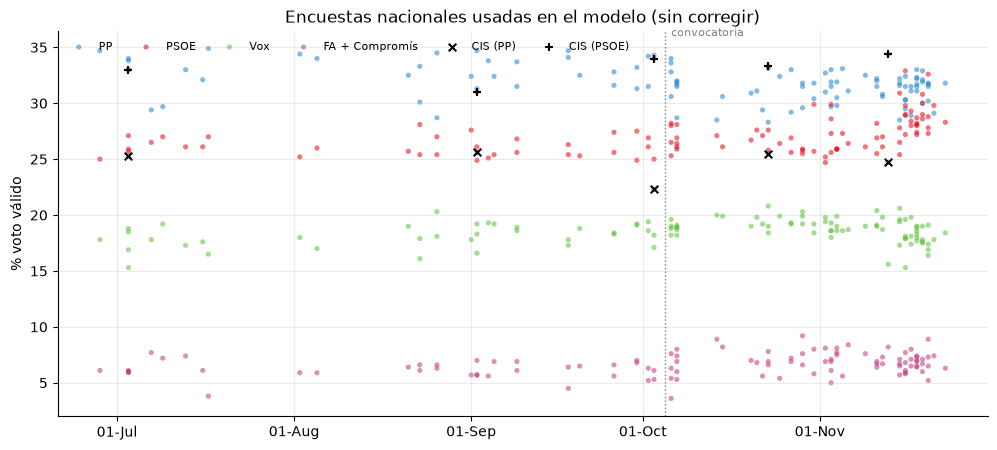

In [9]:
fig, ax = plt.subplots(figsize=(12, 5))
for p in ["PP", "PSOE", "Vox", "FAFV"]:
    ax.scatter(enc.fecha, enc[p], s=14, alpha=.55, color=COLORES[p], label=ETIQ.get(p, p), edgecolor="none")
cis = enc[enc.casa == "CIS"]
ax.scatter(cis.fecha, cis.PP, marker="x", color="k", s=30, label="CIS (PP)")
ax.scatter(cis.fecha, cis.PSOE, marker="+", color="k", s=40, label="CIS (PSOE)")
ax.axvline(CONVOCATORIA, color="grey", ls=":", lw=1); ax.text(CONVOCATORIA + pd.Timedelta(days=1), 36, "convocatoria", fontsize=8, color="grey")
ax.set_ylabel("% voto válido"); ax.set_title("Encuestas nacionales usadas en el modelo (sin corregir)")
ax.legend(ncol=6, fontsize=8, frameon=False, loc="upper left"); ax.grid(alpha=.25); ax.spines[["top", "right"]].set_visible(False)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d-%b")); plt.show()

## 5. Modelo bayesiano de espacio de estados

**Idea.** Existe una intención de voto «real» que cambia poco a poco. Cada encuesta la mide con dos fuentes de error: el azar del muestreo y el sesgo sistemático de su empresa (**efecto casa**: método de ponderación, recuerdo de voto, tipo de panel…).

**Especificación.** Para cada día $t$ y partido $k$ (con «otros» como referencia):

$$\eta_{t,k} = \eta_{t-1,k} + \varepsilon_{t,k},\qquad \varepsilon_{t,k}\sim\mathcal N(0,\sigma_k^{rw})$$

$$\pi_{i} = \operatorname{softmax}\big(\eta_{t_i} + \delta_{h_i},\,0\big)$$

$$\operatorname{logit}(y_{ik}) \sim \mathcal N\!\Big(\operatorname{logit}(\pi_{ik}),\ \sqrt{\tfrac{1}{n_i\,\pi_{ik}(1-\pi_{ik})} + \big(\tfrac{0.00029}{\pi_{ik}(1-\pi_{ik})}\big)^2 + \omega^2}\Big)$$

- $\eta$: intención de voto latente (escala log-ratio). El paseo aleatorio diario permite cambios graduales y se prolonga hasta el día de la elección: los 6 días sin encuestas añaden su propia incertidumbre.
- $\delta_{h}$: efecto casa de la encuestadora $h$, con prior jerárquica $\mathcal N(0,\tau_k)$. **Referencia:** para cada partido, los efectos casa de las empresas privadas **que publican ese partido** suman cero; la estimación representa a la *encuestadora privada media*. (Si la media incluyera empresas que nunca dan, por ejemplo, a Bildu, esas empresas podrían «absorber» la restricción y el nivel del partido quedaría mal identificado.) El CIS queda fuera de la referencia (prior propia más ancha) porque se aparta mucho del resto.
- Varianza: error muestral (aproximación delta) + redondeo a una décima + ruido no muestral $\omega$.
- Los partidos que una encuesta no publica son datos ausentes, no ceros.

**¿Por qué no *machine learning* clásico?** Hay unas pocas decenas de encuestas por partido; un modelo generativo con estructura explícita (tendencia + sesgo de casa + ruido) aprovecha esos pocos datos y da incertidumbre calibrada.

In [10]:
fit26 = ajustar_modelo(enc, PARTIDOS, INICIO_VENTANA, FECHA_ELECCION, draws=DRAWS, tune=TUNE, chains=CHAINS, seed=SEED,
                     sampler=NUTS_SAMPLER)
idata = fit26["idata"]; casas = fit26["casas"]; dias = fit26["dias"]; eta_s = fit26["eta_s"]
print(f"Muestreo ({fit26['sampler']}): {fit26['segundos']:.0f} s")

Muestreo (nutpie): 51 s


### 5.1 Diagnóstico del muestreo
Criterios habituales: $\hat R < 1{,}01$, tamaño efectivo (ESS) > 400 y ninguna transición divergente.

Muestreador: si está instalado se usa **nutpie** (implementación de NUTS compilada con numba: más rápida y sin necesidad de compilador C); si no, el NUTS estándar de PyMC. Ambos muestrean el mismo modelo.

In [11]:
def diagnostico(idata):
    diag = az.summary(idata, var_names=["sigma_rw", "tau", "omega", "delta"], kind="diagnostics")
    fin = az.summary(idata.posterior.eta.isel(dia=-1), kind="diagnostics")
    return dict(divergencias=int(idata.sample_stats.diverging.sum()), rhat_hiper=round(float(diag.r_hat.max()), 3),
                ess_hiper=int(diag.ess_bulk.min()), rhat_dia_E=round(float(fin.r_hat.max()), 3), ess_dia_E=int(fin.ess_bulk.min()),
                criterios_ok=bool(int(idata.sample_stats.diverging.sum()) == 0 and max(diag.r_hat.max(), fin.r_hat.max()) < 1.015
                                  and min(diag.ess_bulk.min(), fin.ess_bulk.min()) > 400))
diagnostico(idata)

{'divergencias': 0,
 'rhat_hiper': 1.01,
 'ess_hiper': 661,
 'rhat_dia_E': 1.0,
 'ess_dia_E': 612,
 'criterios_ok': True}

### 5.2 Tendencia estimada
Mediana e intervalo creíble del 90 % para la *encuestadora privada media*, con las encuestas corregidas por su efecto casa (puntos intensos) y sin corregir (puntos claros).

La caída de Podemos en octubre no es (solo) un cambio de opinión: desde la convocatoria se presenta dentro de ERC en Cataluña y de Compromís–FV en la Comunitat Valenciana, así que las encuestas dejan de atribuirle ese voto.

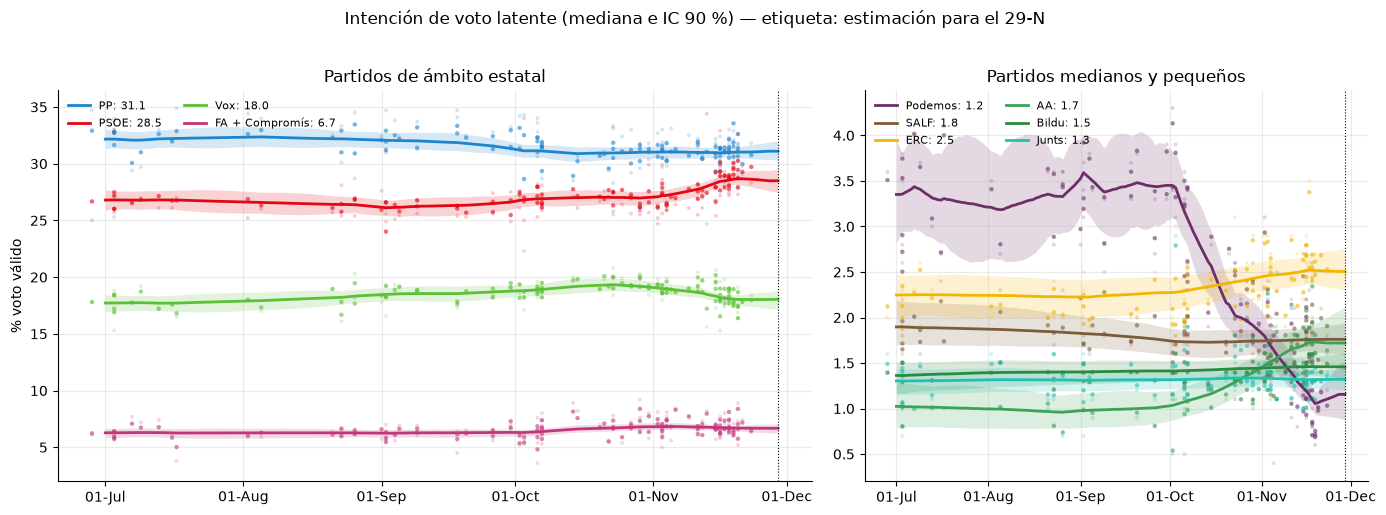

In [12]:
pi_t = softmax_ref(eta_s) * 100
pi_T = fit26["pi_T"]
d_s = fit26["delta_s"]; eta_T = eta_s[:, -1, :]
casa_pts = (softmax_ref(eta_T[:, None, :] + d_s)[:, :, :K] - softmax_ref(eta_T)[:, None, :K]) * 100   # S × H × K
EFECTO_PTS = pd.DataFrame(casa_pts.mean(0), index=casas, columns=PARTIDOS)

fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [3, 2]})
for ax, grupo in zip(axes, [["PP", "PSOE", "Vox", "FAFV"], ["Podemos", "SALF", "ERC", "AA", "Bildu", "Junts"]]):
    for p in grupo:
        k = PARTIDOS.index(p)
        lo, me, hi = np.percentile(pi_t[:, :, k], [5, 50, 95], axis=0)
        ax.fill_between(dias, lo, hi, color=COLORES[p], alpha=.18, lw=0)
        ax.plot(dias, me, color=COLORES[p], lw=2, label=f"{ETIQ.get(p, p)}: {me[-1]:.1f}")
        ok = enc[p].notna()
        ax.scatter(enc.fecha[ok], enc[p][ok], s=8, color=COLORES[p], alpha=.2, edgecolor="none")
        ax.scatter(enc.fecha[ok], enc[p][ok] - EFECTO_PTS.loc[enc.casa[ok], p].to_numpy(), s=10, color=COLORES[p], alpha=.6, edgecolor="none")
    ax.axvline(dias[-1], color="k", lw=.8, ls=":")
    ax.legend(fontsize=8, frameon=False, loc="upper left", ncol=2); ax.grid(alpha=.25)
    ax.spines[["top", "right"]].set_visible(False); ax.xaxis.set_major_formatter(mdates.DateFormatter("%d-%b"))
axes[0].set_ylabel("% voto válido"); axes[0].set_title("Partidos de ámbito estatal"); axes[1].set_title("Partidos medianos y pequeños")
plt.suptitle("Intención de voto latente (mediana e IC 90 %) — etiqueta: estimación para el 29-N", y=1.02)
plt.tight_layout(); plt.show()

### 5.3 Efectos casa: ¿hacia dónde se inclina cada encuestadora?
Diferencia, en **puntos porcentuales**, entre lo que publicaría cada empresa y la estimación de consenso el día de la elección. Positivo = esa casa da a ese partido más que la media de las privadas. Se muestra el medio que publica cada encuesta para conectar con la idea de sesgo editorial; el modelo estima el sesgo por empresa, que es quien diseña la ponderación.

In [13]:
he = EFECTO_PTS.copy()
he_lo = pd.DataFrame(np.percentile(casa_pts, 5, 0), index=casas, columns=PARTIDOS)
he_hi = pd.DataFrame(np.percentile(casa_pts, 95, 0), index=casas, columns=PARTIDOS)
he["PP−PSOE"] = (casa_pts[:, :, 0] - casa_pts[:, :, 1]).mean(0)
he["Derecha−izq."] = (casa_pts[:, :, [0, 2, 5]].sum(-1) - casa_pts[:, :, [1, 3, 4]].sum(-1)).mean(0)
he.insert(0, "medios", resumen_casas.medios.reindex(he.index)); he.insert(1, "n", resumen_casas.encuestas.reindex(he.index))
tabla_he = he.sort_values("PP−PSOE")
tabla_he[["medios", "n", "PP", "PSOE", "Vox", "FAFV", "Podemos", "SALF", "PP−PSOE", "Derecha−izq."]].round(2)

,medios,n,PP,PSOE,Vox,FAFV,Podemos,SALF,PP−PSOE,Derecha−izq.
CIS,—,5,-6.35,6.98,-1.62,0.24,-0.22,0.10,-13.33,-14.87
SW Demoscopia,La Séptima,1,-1.06,2.78,-1.25,-0.13,0.03,0.13,-3.84,-4.85
Cluster17,"Agenda Pública, El Grand Continent",3,-0.90,2.34,-0.58,-0.55,0.02,-0.13,-3.23,-3.42
More in Common,—,3,-2.21,0.11,0.83,0.44,0.14,0.41,-2.31,-1.65
ODEC,Mediaflows–UV,1,-1.30,0.17,0.47,0.47,0.05,-0.13,-1.47,-1.64
AtlasIntel,PollsterGraph,1,-0.88,0.52,-0.02,0.22,0.02,0.11,-1.40,-1.55
40dB,Prisa,5,0.32,1.66,-0.59,-0.89,-0.17,-0.02,-1.35,-0.89
Ipsos,La Vanguardia,1,-0.38,0.92,-0.12,-0.43,-0.02,0.06,-1.30,-0.91
Metroscopia,—,1,-0.57,0.50,0.08,-0.02,0.01,0.00,-1.07,-0.97
Sondaxe,La Voz de Galicia,4,-0.81,-0.13,0.02,0.52,0.03,0.25,-0.68,-0.96


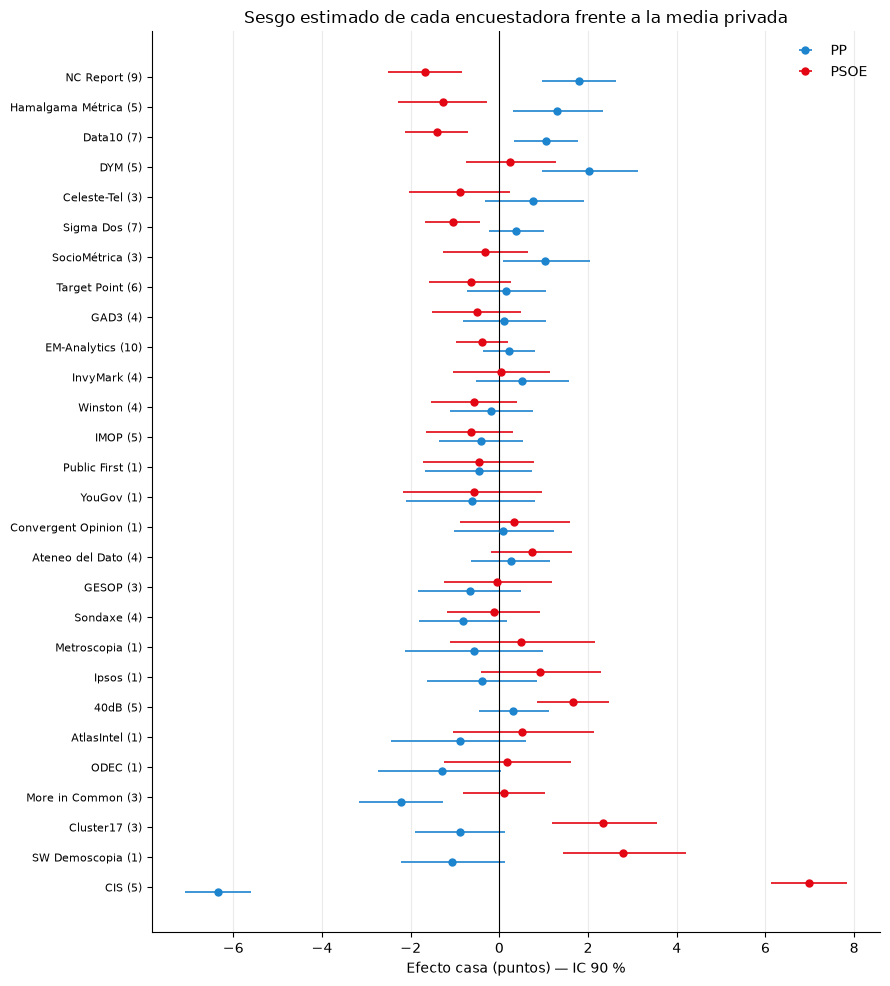

In [14]:
orden = tabla_he.index
fig, ax = plt.subplots(figsize=(9, 0.32 * len(orden) + 1))
y = np.arange(len(orden))
for off, p in [(-0.15, "PP"), (0.15, "PSOE")]:
    ax.errorbar(he.loc[orden, p], y + off, xerr=[he.loc[orden, p] - he_lo.loc[orden, p], he_hi.loc[orden, p] - he.loc[orden, p]],
                fmt="o", ms=5, color=COLORES[p], elinewidth=1.2, capsize=0, label=p)
ax.axvline(0, color="k", lw=.8); ax.set_yticks(y); ax.set_yticklabels([f"{c} ({int(he.loc[c, 'n'])})" for c in orden], fontsize=8)
ax.set_xlabel("Efecto casa (puntos) — IC 90 %"); ax.set_title("Sesgo estimado de cada encuestadora frente a la media privada")
ax.legend(frameon=False); ax.grid(axis="x", alpha=.25); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

### 5.4 Estimación nacional para el 29-N
Es la estimación *de las encuestas corregidas*. Todavía no incluye el riesgo de que **todas** se equivoquen en la misma dirección (sección 6).

In [15]:
nac = pd.DataFrame(pi_T * 100, columns=PARTIDOS + ["OTROS"])
ult = enc[enc.fin >= FECHA_ELECCION - pd.Timedelta(days=13)]
tabla_nac = pd.DataFrame({"media": nac.mean(), "IC90_inf": nac.quantile(.05), "IC90_sup": nac.quantile(.95),
                          "media_simple_ult_semana": ult[PARTIDOS].mean()}).round(2)
tabla_nac

,media,IC90_inf,IC90_sup,media_simple_ult_semana
AA,1.74,1.41,2.11,1.77
BNG,0.95,0.85,1.05,0.93
Bildu,1.46,1.34,1.60,1.52
CCa,0.43,0.37,0.49,0.38
ERC,2.51,2.30,2.76,2.64
FAFV,6.67,6.24,7.08,6.82
Junts,1.32,1.21,1.44,1.24
OTROS,3.46,3.07,3.86,NaN
PNV,0.89,0.78,0.99,0.82
PP,31.11,30.29,31.98,31.00


## 6. Error sistemático: cuando fallan todas a la vez

Corregir los efectos casa centra las encuestas en la **media de la industria**, pero la media también falla. Lo medimos con la media de las encuestas privadas de la última semana legal (una por empresa, la más reciente, sin CIS) frente al resultado real.

In [16]:
FECHAS_ELEC = {"2015": dt.date(2015, 12, 20), "2016": dt.date(2016, 6, 26), "April 2019": dt.date(2019, 4, 28),
               "November 2019": dt.date(2019, 11, 10), "2023": dt.date(2023, 7, 23)}
MAPA_HIST = {"PP": ["PP"], "PSOE": ["PSOE"], "Vox": ["Vox"],
             "IZQ": ["Sumar", "Unidas Podemos", "Unidos Podemos", "Podemos"], "Cs": ["Cs", "C's"]}
filas, finales23 = [], None
for e, fe in FECHAS_ELEC.items():
    h = D["hist"][D["hist"].eleccion == e].copy()
    res = h.iloc[0]; h = h.iloc[1:]
    h["fin"] = [parse_range(x, fe.year)[1] for x in h.date]
    ban = fe - dt.timedelta(days=6)
    h["casa"] = h.firm.str.split("/").str[0].str.strip()
    h = h[h.fin.notna() & (h.fin <= ban) & (h.fin >= ban - dt.timedelta(days=10)) & ~h.casa.str.startswith("CIS")
          & ~h.casa.isin(PARTIDOS_ENCARGANTES) & h["PP"].notna()]
    h = h.sort_values("fin").groupby("casa").tail(1)
    if e == "2023": finales23 = h
    for p, cands in MAPA_HIST.items():
        c = next((c for c in cands if c in h.columns and pd.notna(res.get(c))), None)
        if c is None: continue
        filas.append(dict(eleccion=e, partido=p, resultado=res[c], media_encuestas=h[c].mean(), n_casas=h[c].notna().sum()))
err = pd.DataFrame(filas)
err["error_pts"] = err.media_encuestas - err.resultado
lg = lambda x: np.log(x / (100 - x))
err["error_logit"] = lg(err.media_encuestas) - lg(err.resultado)
SIGMA_SIST = float(np.sqrt((err.error_logit ** 2).mean()))
print(f"Error sistemático típico (RMS, escala logit): {SIGMA_SIST:.3f}  ≈ {SIGMA_SIST*0.21*100:.1f} puntos para un partido del 30 %")

# ¿Fallan en bloque? Correlación del error entre partidos del mismo bloque (derecha +1, izquierda −1)
BLOQUE_HIST = {"PP": 1, "Vox": 1, "Cs": 1, "PSOE": -1, "IZQ": -1}
def estimar_rho(err, sigma):
    """Método de momentos: media de x_i·x_j (i ≠ j, misma elección) con x = signo de bloque × error logit,
    dividida por σ². 0 = errores independientes; 1 = todo el error es común al bloque."""
    num = den = 0.0
    for _, g in err.groupby("eleccion"):
        x = (g.set_index("partido").error_logit * pd.Series(BLOQUE_HIST)).dropna().to_numpy()
        num += x.sum() ** 2 - (x ** 2).sum(); den += len(x) * (len(x) - 1)
    return float(np.clip(num / den / sigma ** 2, 0, 0.9))

RHO_EST = estimar_rho(err, SIGMA_SIST)
RHO = RHO_EST if RHO_BLOQUE is None else RHO_BLOQUE
VEC_BLOQUE = np.array([BLOQUE.get(p, 0) for p in PARTIDOS])
brecha_hist = (err.assign(b=err.partido.map(BLOQUE_HIST)).dropna(subset=["b"])
               .assign(x=lambda d: d.b * d.error_pts).groupby("eleccion").x.sum().reindex(FECHAS_ELEC))
BRECHA_HIST_RMS = float(np.sqrt((brecha_hist ** 2).mean()))
print(f"Correlación de bloque estimada: ρ = {RHO_EST:.2f} → se usa ρ = {RHO:.2f}")
print("Error en la brecha derecha − izquierda (pts; + = favoreció a la derecha): "
      + ", ".join(f"{e} {v:+.1f}" for e, v in brecha_hist.items()) + f"  | RMS {BRECHA_HIST_RMS:.1f}")
err.pivot(index="eleccion", columns="partido", values="error_pts").reindex(FECHAS_ELEC).round(2)

Error sistemático típico (RMS, escala logit): 0.158  ≈ 3.3 puntos para un partido del 30 %
Correlación de bloque estimada: ρ = 0.04 → se usa ρ = 0.04
Error en la brecha derecha − izquierda (pts; + = favoreció a la derecha): 2015 +8.6, 2016 -4.2, April 2019 +4.3, November 2019 +1.8, 2023 +4.6  | RMS 5.2


partido,Cs,IZQ,PP,PSOE,Vox
eleccion,,,,,
2015,5.26,-3.06,-1.32,-1.59,NaN
2016,1.19,3.49,-3.29,-1.42,NaN
April 2019,-1.09,-1.13,3.95,0.29,0.64
November 2019,2.36,-0.56,0.15,-0.76,-1.99
2023,NaN,0.86,1.17,-3.53,0.77


Un signo **positivo** significa que las encuestas **sobrestimaron** al partido. En 2023 la media privada infravaloró al PSOE en unos 3,5 puntos; en abril de 2019 sobrestimó al PP en casi 4 y en 2016 lo infravaloró en más de 3. No hay un patrón fijo, por eso el modelo trata este error como **aleatorio, con colas gruesas** (t de Student, 5 g.l.) y desviación típica `SIGMA_SIST`. La réplica exacta de 2023 se estudia aparte (sección 10).

**¿Fallan en bloque?** Si las encuestas sobrestiman a la derecha, ¿infravaloran a la vez a la izquierda? Se estima la correlación $\rho$ entre los errores (en escala logit) de partidos del mismo bloque (derecha: PP, Vox, Cs; izquierda: PSOE y el espacio a su izquierda). En la simulación, una fracción $\rho$ de la varianza del error de cada partido es común a su bloque, con signo opuesto entre bloques; la varianza de cada partido no cambia. Con cinco elecciones la estimación es imprecisa (y `Cs` pesa mucho en 2015), así que en la sección 9.3 se comprueba si la incertidumbre final sobre la brecha derecha–izquierda es coherente con la histórica. En puntos, la brecha favoreció a la derecha en 4 de 5 elecciones, pero con una media de unos 3 puntos y una dispersión de casi 5 no es una pauta distinguible del azar: el modelo **no** corrige en ninguna dirección.

**Historial de las casas en 2023** (error de su última encuesta, en puntos; + = sobrestimó). Es contexto, no entra en el modelo.

In [17]:
hist_casas = finales23[["casa", "PP", "PSOE", "Vox", "Sumar"]].copy()
r23h = D["hist"][D["hist"].eleccion == "2023"].iloc[0]
for p in ["PP", "PSOE", "Vox", "Sumar"]: hist_casas[p] = hist_casas[p] - r23h[p]
hist_casas["error_abs_medio"] = hist_casas[["PP", "PSOE", "Vox", "Sumar"]].abs().mean(axis=1)
hist_casas = hist_casas.set_index("casa").sort_values("error_abs_medio")
hist_casas["efecto_casa_2026_PP−PSOE"] = he["PP−PSOE"].reindex(hist_casas.index)
hist_casas.round(2)

,PP,PSOE,Vox,Sumar,error_abs_medio,efecto_casa_2026_PP−PSOE
casa,,,,,,
40dB,-0.2,-3.0,1.1,1.4,1.43,-1.35
Cluster17,0.5,-2.8,1.3,1.2,1.45,-3.23
EM-Analytics,1.4,-2.9,0.5,1.1,1.47,0.60
SocioMétrica,0.4,-3.4,1.3,0.9,1.50,1.35
Sondaxe,1.2,-3.0,0.1,1.7,1.50,-0.68
KeyData,1.6,-3.7,0.5,0.5,1.58,NaN
IMOP,-0.2,-3.5,2.1,0.5,1.58,0.23
Simple Lógica,-0.9,-3.1,1.5,1.5,1.75,NaN
Target Point,3.3,-3.6,0.0,-0.2,1.77,0.79


## 7. Del voto nacional al provincial

### 7.1 Base provincial adaptada a las candidaturas de 2026

| Candidatura 2026 | Geografía de partida |
|---|---|
| PP | PP 2023 + UPN 2023 (Navarra; concurren juntos) |
| PSOE, Vox, ERC, Junts, Bildu, PNV, BNG, CCa | su resultado de 2023 (Vox no se presentó en Santa Cruz de Tenerife en 2023: se imputa con su voto de 2019 escalado) |
| FA (Frente Amplio) | Sumar 2023, salvo Comunitat Valenciana (va dentro de Compromís–FV) y Teruel (CHA–FA no se presenta) |
| Compromís–FV | Sumar 2023, solo en Alicante, Castellón y Valencia |
| Podemos | Sumar 2023, salvo Cataluña (va con ERC), C. Valenciana (dentro de FV), Canarias y Baleares (integrado en FA) |
| SALF | geografía de Vox 2023 (electorado de perfil parecido; sin resultados generales previos) |
| Adelante Andalucía | su resultado por provincia en las autonómicas andaluzas de 2026 |
| Otros (incluye voto en blanco) | resto de 2023 |

Solo importa la **forma geográfica** de esta base: el nivel lo fija la estimación nacional de cada simulación (*swing* proporcional con *raking*, de modo que la suma ponderada por votos válidos reproduce exactamente el voto nacional).

In [18]:
NOMBRE_ES = {"Seville": "Sevilla", "Biscay": "Bizkaia", "Navarre": "Navarra", "Balearic Islands": "Illes Balears", "Álava": "Araba/Álava",
             "Andalusia": "Andalucía", "Aragon": "Aragón", "Basque Country": "País Vasco", "Canary Islands": "Canarias",
             "Castile and León": "Castilla y León", "Catalonia": "Cataluña", "Valencian Community": "Comunitat Valenciana"}
REGION_ES = {"AND": "Andalucía", "ARA": "Aragón", "AST": "Asturias", "BAL": "Illes Balears", "PVA": "País Vasco", "CAN": "Canarias",
             "CNT": "Cantabria", "CYL": "Castilla y León", "CLM": "Castilla-La Mancha", "CAT": "Cataluña", "EXT": "Extremadura",
             "GAL": "Galicia", "RIO": "La Rioja", "MAD": "Madrid", "MUR": "Murcia", "NAV": "Navarra", "VAL": "C. Valenciana",
             "CEU": "Ceuta", "MEL": "Melilla"}
res23 = D["res23"].set_index("prov"); res19 = D["res19"].set_index("prov"); res16 = D["res16"].set_index("prov")
tot23 = res23.loc["Total"]; res23 = res23.drop("Total"); tot19 = res19.loc["Total"]; res19 = res19.drop("Total")
tot16 = res16.loc["Total"]; res16 = res16.drop("Total")
PROV = list(res23.index); assert set(PROV) == set(REGION)
escanos26 = D["escanos26"].reindex(PROV).astype(int); assert escanos26.sum() == 350

def dhondt(votos, n, umbral=3.0):
    v = np.where(votos >= umbral, votos, 0.0)
    q = (v[:, None] / np.arange(1, n + 1)[None, :]).ravel()
    return np.bincount(np.argsort(-q, kind="stable")[:n] // n, minlength=len(v))
P23 = ["PP","PSOE","Vox","Sumar","ERC","Junts","Bildu","PNV","BNG","CCa","UPN"]
esc23_sim = sum(dhondt(res23.loc[p, P23].to_numpy(float), int(res23.loc[p, ["S_" + x for x in P23]].sum())) for p in PROV)
print("Validación D'Hondt 2023 →", dict(zip(P23, esc23_sim.astype(int))), "| coincide con el real:",
      bool((esc23_sim == res23[["S_" + x for x in P23]].sum().to_numpy()).all()))

reg = pd.Series(REGION).reindex(PROV)
base26 = pd.DataFrame(0.0, index=PROV, columns=CAND)
base26["PP"] = res23.PP + res23.UPN
for p in ["PSOE", "Vox", "ERC", "Junts", "Bildu", "PNV", "BNG", "CCa"]: base26[p] = res23[p]
base26.loc["Santa Cruz de Tenerife", "Vox"] = res19.loc["Santa Cruz de Tenerife", "Vox"] * tot23.Vox / tot19.Vox
izq = res23.Sumar
base26["FA"] = np.where(reg.eq("VAL") | (base26.index == "Teruel"), 0, izq)
base26["FV"] = np.where(reg.eq("VAL"), izq, 0)
base26["Podemos"] = np.where(reg.isin(["VAL", "CAT", "CAN", "BAL"]), 0, izq)
base26["SALF"] = base26.Vox
base26["AA"] = [D["aa26"].get(p, 0.0) if reg[p] == "AND" else 0.0 for p in PROV]
base26["OTROS"] = (100 - res23[P23].sum(axis=1)).clip(lower=0.5)
base26.round(1).head()

Validación D'Hondt 2023 → {'PP': np.int64(137), 'PSOE': np.int64(121), 'Vox': np.int64(33), 'Sumar': np.int64(31), 'ERC': np.int64(7), 'Junts': np.int64(7), 'Bildu': np.int64(6), 'PNV': np.int64(5), 'BNG': np.int64(1), 'CCa': np.int64(1), 'UPN': np.int64(1)} | coincide con el real: True


,PP,PSOE,Vox,FA,FV,Podemos,SALF,ERC,Junts,Bildu,PNV,BNG,CCa,AA,OTROS
A Coruña,43.1,28.2,5.1,12.2,0.0,12.2,5.1,0.0,0.0,0.0,0.0,10.0,0.0,0.0,1.4
Álava,17.9,27.7,3.9,12.7,0.0,12.7,3.9,0.0,0.0,19.5,16.6,0.0,0.0,0.0,1.7
Albacete,39.9,34.5,16.6,7.2,0.0,7.2,16.6,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.8
Alicante,36.7,32.0,16.3,0.0,12.9,0.0,16.3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.1
Almería,41.0,29.0,21.4,6.6,0.0,6.6,21.4,0.0,0.0,0.0,0.0,0.0,0.0,3.1,2.0


### 7.2 Cuánto se aparta cada provincia del *swing* nacional
Si un partido sube un 10 % en España, no sube exactamente un 10 % en cada provincia. Medimos esas desviaciones en el ciclo anterior (2019→2023; PP, PSOE, Vox y el espacio a la izquierda del PSOE), separando un componente **regional** (comunidad autónoma) y otro **provincial**. Se usan como ruido en la simulación y como *prior* del ajuste con encuestas autonómicas (sección 8).

In [19]:
def calibrar_ruido(nuevo, viejo, tot_n, tot_v, pares):
    devs = []
    for p, (a, b) in pares.items():
        nat = np.log(tot_n[a] / tot_v[b])
        for prov in nuevo.index:
            x, y = nuevo.loc[prov, a], viejo.loc[prov, b]
            if x > 0 and y > 0: devs.append(dict(partido=p, reg=REGION[prov], dev=np.log(x / y) - nat))
    devs = pd.DataFrame(devs)
    comp = pd.DataFrame([dict(partido=p, sd_regional=g.groupby("reg").dev.mean().std(),
                              sd_provincial=(g.dev - g.groupby("reg").dev.transform("mean")).std()) for p, g in devs.groupby("partido")]).set_index("partido")
    return float(comp.sd_regional.mean()), float(comp.sd_provincial.mean()), comp

r19x = res19.assign(IZQ=res19.UP + res19.MP); t19x = tot19.copy(); t19x["IZQ"] = tot19.UP + tot19.MP
SD_REG, SD_PROV, comp26 = calibrar_ruido(res23.assign(IZQ=res23.Sumar), r19x, pd.concat([tot23, pd.Series({"IZQ": tot23.Sumar})]), t19x,
                                         {"PP": ("PP", "PP"), "PSOE": ("PSOE", "PSOE"), "Vox": ("Vox", "Vox"), "IZQ": ("IZQ", "IZQ")})
print(f"Ruido regional σ = {SD_REG:.3f}   provincial σ = {SD_PROV:.3f}   (escala log)")
comp26.round(3)

Ruido regional σ = 0.152   provincial σ = 0.065   (escala log)


,sd_regional,sd_provincial
partido,,
IZQ,0.154,0.101
PP,0.105,0.062
PSOE,0.172,0.046
Vox,0.178,0.051


In [20]:
def a_cand26(pin, rng):
    """Proporciones nacionales del modelo (PARTIDOS+OTROS) → candidaturas (separa FA y FV)."""
    S = pin.shape[0]
    fv = np.full(S, FV_MU) if rng is None else np.clip(rng.normal(FV_MU, FV_SE, S), 0.05, 0.6)
    out = np.zeros((S, len(CAND)))
    for j, c in enumerate(CAND):
        if c == "FA": out[:, j] = pin[:, PARTIDOS.index("FAFV")] * (1 - fv)
        elif c == "FV": out[:, j] = pin[:, PARTIDOS.index("FAFV")] * fv
        elif c == "OTROS": out[:, j] = pin[:, -1]
        else: out[:, j] = pin[:, PARTIDOS.index(c)]
    return out
mapa26 = Mapa(base26, D["validos23"], escanos26, SD_REG, SD_PROV, CAND, a_cand26)
print(f"FV / (FA+FV) = {FV_MU:.3f} ± {FV_SE:.3f} ({len(FV_RATIO)} encuestas que los separan)")

FV / (FA+FV) = 0.196 ± 0.009 (70 encuestas que los separan)


## 8. Encuestas autonómicas y provinciales

Wikipedia recoge encuestas de las generales publicadas solo para una comunidad o una provincia (Sondaxe en Galicia, Ikerfel en Euskadi, Social Data en Andalucía, CEMOP en Murcia, Demoscopia Servicios en la C. Valenciana…). Aportan lo que la encuesta nacional no ve: **dónde** sube o baja cada partido.

**Método (normal–normal, explícito):**
1. Para cada encuesta subnacional, se calcula lo que *esperaría* el modelo en ese territorio y fecha: voto nacional de consenso de ese día × geografía base (sin ruido).
2. Desviación observada: $d = \log(\text{encuesta}/\text{esperado})$, con varianza $\frac{1-y}{n\,y} + \sigma_{casa}^2$. El segundo término (`SIGMA_CASA_SUB`) recoge el error no muestral de estas casas, cuyo sesgo no se puede estimar con tan pocas encuestas; su tamaño se **calibra con 2023** (sección 8.1). Si la empresa también publica encuestas nacionales (EM-Analytics, GESOP, DYM, Target Point, SocioMétrica…), antes se descuenta su efecto casa estimado en la sección 5.
3. Se combina con la *prior* de la sección 7.2: $\mathcal N(0,\sigma_{reg}^2)$ para comunidades y $\mathcal N(\mu_{reg},\, v_{reg}+\sigma_{prov}^2)$ para provincias. La media posterior es una media ponderada: pocas encuestas o muy ruidosas → se mueve poco.
4. En la simulación, el ruido territorial deja de estar centrado en cero y pasa a estar centrado en esas desviaciones posteriores (y con menos varianza).

Solo se usan encuestas publicadas **desde la convocatoria** (con las coaliciones ya cerradas) y se eliminan solapamientos de los *trackings* territoriales. Los partidos se traducen a las candidaturas de 2026 de cada territorio (PSC/PSdeG → PSOE; CHA y UPC → FA; Compromís y Podemos en la C. Valenciana → FV; Podem en Cataluña → ERC…).

### 8.1 ¿Cuánto se equivoca una encuesta subnacional? Calibración con 2023
Antes de usar las encuestas autonómicas y provinciales hay que saber cuánto ruido traen además del muestral. Se comparan las de la campaña de 2023 con el **resultado real** de su territorio, descontando el error común que tuvieron ese año las encuestas nacionales para cada partido (si todas infravaloraron al PSOE, eso no es culpa de la encuesta gallega). Lo que sobra por encima del error muestral es `SIGMA_CASA_SUB`.

Aquí se definen también las piezas de 2023 que reutiliza la prueba hacia atrás (sección 11).

In [21]:
FE23 = pd.Timestamp("2023-07-23"); INI23 = FE23 - (FECHA_ELECCION - INICIO_VENTANA); CONV23 = pd.Timestamp("2023-05-30")
SUMAR23 = {"Unidas Podemos", "Podemos", "IU", "Más País", "Mas País–CHA–Equo", "Sumar", "ECP", "EC", "Elkarrekin Podemos",
           "Més Compromís", "Sumem per Guanyar", "Ara Més"}
def mapear23(col, unidad):
    c = col.strip()
    if c == "PP": return "PP"
    if "PSOE" in c or c == "PSC": return "PSOE"
    if c in SUMAR23: return "Sumar"
    if c in ("JxCat", "Junts"): return "Junts"
    if c == "EH Bildu": return "Bildu"
    if c in ("CC–NCa", "CCa"): return "CCa"
    if c in ("Vox", "ERC", "CUP", "PNV", "BNG", "UPN"): return c
    return None
sub23 = preparar_subnacionales(D["sub23_raw"], mapear23, 2023, CONV23, FE23, {**CFG, "PRIORIDAD_SUB": {}})

def calibrar_sigma_sub(sub, res, validos, finales, real_nac, umbral=3.0):
    """Residuo de cada cifra = log(encuesta / resultado real del territorio) − error nacional común de ese partido.
    σ² = media(residuo² − varianza muestral). Solo partidos con ≥ umbral % en el territorio."""
    filas = []
    for _, r in sub.iterrows():
        if r.cand not in res.columns or r.valor <= 0: continue
        if r.nivel == "region":
            code = NOMBRE_REGION.get(r.unidad); provs = [p for p in res.index if REGION[p] == code]
        else:
            provs = [r.unidad] if r.unidad in res.index else []
        if not provs: continue
        w = validos.reindex(provs).to_numpy(float)
        real = float(w @ res.loc[provs, r.cand].to_numpy(float) / w.sum())
        if real < umbral: continue
        col = r.cand if r.cand in finales.columns else {"Bildu": "EH Bildu"}.get(r.cand, r.cand)
        ok = col in finales.columns and pd.notna(real_nac.get(col)) and finales[col].notna().any()
        nac = float(np.log(finales[col].mean() / real_nac[col])) if ok else 0.0
        y = r.valor / 100
        filas.append(dict(unidad=r.unidad, nivel=r.nivel, cand=r.cand, casa=r.casa, encuesta=r.valor, real=round(real, 2),
                          error_nacional_log=nac, residuo=np.log(r.valor / real) - nac, var_muestral=(1 - y) / (r.n_eff * y)))
    cal = pd.DataFrame(filas)
    s2 = float((cal.residuo ** 2 - cal.var_muestral).mean())
    return float(np.sqrt(max(s2, 0.05 ** 2))), cal

SIGMA_CASA_SUB_CAL, cal_sub = calibrar_sigma_sub(sub23, res23, D["validos23"], finales23, r23h)
CFG["SIGMA_CASA_SUB"] = SIGMA_CASA_SUB_CAL
print(f"{len(cal_sub)} cifras de {cal_sub[['unidad', 'casa']].drop_duplicates().shape[0]} encuestas subnacionales de 2023 comparadas con el resultado real")
print(f"Error no muestral de una encuesta subnacional: σ = {SIGMA_CASA_SUB_CAL:.3f} (≈ ±{100 * (np.exp(SIGMA_CASA_SUB_CAL) - 1):.0f} % "
      f"del voto de cada partido) | valor a priori: {SIGMA_CASA_SUB_PRIOR:.2f}")
(cal_sub.assign(unidad=cal_sub.unidad.replace(NOMBRE_ES), error_pts=cal_sub.encuesta - cal_sub.real)
        .groupby("cand").agg(cifras=("residuo", "size"), error_medio_pts=("error_pts", "mean"), residuo_rms=("residuo", lambda s: np.sqrt((s ** 2).mean())))
        .round(3).sort_values("cifras", ascending=False))

121 cifras de 21 encuestas subnacionales de 2023 comparadas con el resultado real
Error no muestral de una encuesta subnacional: σ = 0.123 (≈ ±13 % del voto de cada partido) | valor a priori: 0.15


,cifras,error_medio_pts,residuo_rms
cand,,,
Sumar,26,-0.280,0.228
PSOE,26,-2.958,0.072
PP,26,0.677,0.111
Vox,18,-0.291,0.176
Bildu,9,0.989,0.085
PNV,8,3.190,0.082
BNG,2,1.270,0.193
ERC,2,2.410,0.043
Junts,2,1.770,0.103


In [22]:
IZQ_COLS = ("Sumar", "FA", "FV", "Compromís", "Sumem per Guanyar", "Ara Més", "CHA", "UPC", "NCa", "Podemos", "Podem")
def mapear26(col, unidad):
    rg = NOMBRE_REGION.get(unidad) or REGION.get(unidad); c = col.strip()
    if c in ("PP", "UPN"): return "PP"
    if "PSOE" in c or c == "PSC": return "PSOE"
    if c == "EH Bildu": return "Bildu"
    if c in ("Vox", "PNV", "ERC", "Junts", "BNG", "CCa", "SALF"): return c
    if c.startswith("Adelante Andaluc"): return "AA"
    if c in IZQ_COLS:
        if rg == "VAL": return "FV"
        if rg == "CAT": return "ERC" if c in ("Podem", "Podemos") else "FA"
        if rg in ("CAN", "BAL"): return "FA"
        return "Podemos" if c == "Podemos" else "FA"
    return None   # UPL, Existe, Geroa Bai, CUP, Aliança… → otros (no se presentan o no tienen base)

sub26 = preparar_subnacionales(D["sub26_raw"], mapear26, 2026, CONVOCATORIA, FECHA_ELECCION, CFG)
obs26 = ajuste_regional(sub26, mapa26, fit26, CFG, INICIO_VENTANA, cand_a_partido={"FA": "FAFV", "FV": "FAFV"})
enc_sub = sub26[["firm", "date", "unidad", "nivel"]].drop_duplicates()
print(f"{len(enc_sub)} encuestas subnacionales ({(enc_sub.nivel=='region').sum()} autonómicas, {(enc_sub.nivel=='province').sum()} provinciales) "
      f"en {enc_sub.unidad.nunique()} territorios; {len(obs26)} cifras de partido usadas")
print(f"{(obs26.corr_casa != 0).sum()} cifras corregidas con el efecto casa nacional de su empresa "
      f"({', '.join(sorted(obs26.loc[obs26.corr_casa != 0, 'casa'].unique()))})")
enc_sub.groupby(["nivel", "unidad"]).firm.apply(lambda s: ", ".join(sorted(set(s)))).to_frame("encuestas").rename(index=NOMBRE_ES)

49 encuestas subnacionales (22 autonómicas, 27 provinciales) en 27 territorios; 242 cifras de partido usadas
91 cifras corregidas con el efecto casa nacional de su empresa (DYM, EM-Analytics, GESOP, SocioMétrica, Sondaxe, Target Point)


encuestas
nivel    unidad                                                                   
province A Coruña                                        Sondaxe/La Voz de Galicia
         Alicante                Demoscopia Servicios/Mitjans, SyM Consulting/EPDA
         Almería                                            Social Data/Grupo Viva
         Bizkaia                                                       Ikerfel/GPS
         Castellón               Demoscopia Servicios/Mitjans, SyM Consulting/EPDA
         Cádiz                    EM-Analytics/Electomanía, Social Data/Grupo Viva
         Córdoba                                            Social Data/Grupo Viva
         Gipuzkoa                                                      Ikerfel/GPS
         Granada                                            Social Data/Grupo Viva
         Las Palmas                  GCEMOP/Atlántico Hoy, Perfiles/Prensa Ibérica
         León                                      SyM Consulting/La Nueva Crónica
         Lugo                                            Sondaxe/La Voz de Galicia
         Ourense                                         Sondaxe/La Voz de Galicia
         Pontevedra                                      Sondaxe/La Voz de Galicia
         Santa Cruz de Tenerife      GCEMOP/Atlántico Hoy, Perfiles/Prensa Ibérica
         Valencia                Demoscopia Servicios/Mitjans, SyM Consulting/EPDA
         Araba/Álava                                                   Ikerfel/GPS
region   Andalucía                              CENTRA/CEA, Social Data/Grupo Viva
         Aragón                      A+M/Heraldo de Aragón, Social Data/Grupo Viva
         País Vasco                          EM-Analytics/Electomanía, Ikerfel/GPS
         Canarias                GCEMOP/Atlántico Hoy, Perfiles/Prensa Ibérica,...
         Cataluña                              EM-Analytics/Electomanía, GESOP/CEO
         Galicia                 EM-Analytics/Electomanía, Sondaxe/La Voz de Ga...
         Madrid                    DYM/Justice Europe, Target Point/Justice Europe
         Murcia                                                  CEMOP, OBEDE/UCAM
         Navarra                                          EM-Analytics/Electomanía
         Comunitat Valenciana    Demoscopia Servicios/Mitjans, SocioMétrica/El ...

**Desviaciones territoriales estimadas** (en % sobre lo que daría el *swing* uniforme; 0 = sin encuestas o sin desviación). Ejemplos de lectura: +40 % para FA en Aragón significa que, con el mismo voto nacional, FA obtendría allí un 40 % más de lo que le asignaría la geografía de 2023 (efecto de la candidatura CHA–FA).

In [23]:
efectos_reg = pd.DataFrame((np.exp(mapa26.mu_reg) - 1) * 100, index=[REGION_ES[c] for c in mapa26.reg_codes], columns=CAND).drop(columns="OTROS")
efectos_reg = efectos_reg.loc[(efectos_reg.abs() > 0.05).any(axis=1), (efectos_reg.abs() > 0.05).any(axis=0)].round(0)
efectos_prov = pd.DataFrame((np.exp(mapa26.mu_prov) - 1) * 100, index=mapa26.PROV, columns=CAND).where(~np.isnan(mapa26.var_prov))
efectos_prov = efectos_prov.dropna(how="all").dropna(axis=1, how="all").round(0).rename(index=NOMBRE_ES)
display(efectos_reg.style.background_gradient(cmap="RdBu_r", vmin=-60, vmax=60).format("{:+.0f}"))
display(efectos_prov.style.background_gradient(cmap="RdBu_r", vmin=-60, vmax=60).format("{:+.0f}", na_rep=""))

,PP,PSOE,Vox,FA,FV,Podemos,SALF,ERC,Junts,Bildu,PNV,BNG,CCa,AA
Andalucía,-1,-0,-13,+0,+0,-27,+20,+0,+0,+0,+0,+0,+0,-0
Aragón,-0,+5,-9,+57,+0,+0,+0,+0,+0,+0,+0,+0,+0,+0
Canarias,-12,-4,+1,+55,+0,+0,+0,+0,+0,+0,+0,+0,+7,+0
Cataluña,-1,+0,-4,-6,+0,+0,+0,+16,+9,+0,+0,+0,+0,+0
Galicia,+0,+2,+9,+4,+0,-6,-2,+0,+0,+0,+0,+4,+0,+0
Madrid,-10,-2,-11,+28,+0,-24,+0,+0,+0,+0,+0,+0,+0,+0
Murcia,+1,+6,-4,+5,+0,-5,-0,+0,+0,+0,+0,+0,+0,+0
Navarra,-1,+2,+13,-3,+0,-8,+0,+0,+0,+6,+0,+0,+0,+0
País Vasco,-2,-2,+1,-13,+0,-8,+0,+0,+0,+7,+9,+0,+0,+0
C. Valenciana,+1,-2,-5,+0,+13,+0,+4,+0,+0,+0,+0,+0,+0,+0


,PP,PSOE,Vox,FA,FV,Podemos,SALF,Bildu,PNV,BNG,CCa,AA
A Coruña,+0,+5,+11,,,,,,,+4,,
Araba/Álava,-0,+0,-7,-19,,-14,,+10,+10,,,
Alicante,+0,-3,-10,,+35,,+3,,,,,
Almería,+2,+5,-14,-1,,,,,,,,-0
Bizkaia,-1,-2,+1,-20,,-24,,+10,+9,,,
Cádiz,-1,+3,-15,+10,,-27,+17,,,,,+11
Castellón,+5,+1,-9,,+12,,+2,,,,,
Córdoba,+1,+3,-13,-3,,,,,,,,-1
Gipuzkoa,-4,-2,+7,-20,,-20,,+8,+9,,,
Granada,+1,+4,-14,-3,,,,,,,,-1


Comparación directa encuesta vs. expectativa del modelo en algunos territorios (media de las encuestas de cada territorio):

In [24]:
(obs26.assign(unidad=obs26.unidad.replace(NOMBRE_ES)).groupby(["unidad", "cand"]).agg(n=("dev", "size"), encuesta=("encuesta", "mean"), esperado_swing=("esperado", "mean"))
      .assign(diferencia=lambda d: d.encuesta - d.esperado_swing).round(1)
      .query("abs(diferencia) >= 2").sort_values("diferencia"))

n  encuesta  esperado_swing  diferencia
unidad                 cand                                            
Santa Cruz de Tenerife PP       2      23.5            32.4        -8.9
Las Palmas             Vox      1      17.0            22.7        -5.7
                       PSOE     2      25.0            29.6        -4.6
Madrid                 Podemos  1       2.1             6.6        -4.5
                       Vox      1      16.5            21.0        -4.5
Almería                Vox      1      25.4            29.8        -4.4
Canarias               PP       3      24.0            28.4        -4.3
León                   Vox      1      15.5            19.7        -4.2
Madrid                 PP       1      33.8            37.9        -4.1
Andalucía              Vox      2      17.6            21.3        -3.7
Cádiz                  Vox      2      16.7            20.3        -3.6
Alicante               Vox      2      20.5            24.0        -3.5
Granada                Vox      1      19.2            22.7        -3.5
Las Palmas             PP       2      21.5            24.7        -3.2
Castellón              Vox      2      20.7            23.6        -2.9
Araba/Álava            FA       1       4.3             7.2        -2.9
Córdoba                Vox      1      16.8            19.7        -2.9
Aragón                 Vox      2      19.1            21.7        -2.6
Lugo                   PP       2      45.0            47.7        -2.6
Gipuzkoa               FA       1       3.6             6.1        -2.5
León                   PSOE     1      25.9            28.3        -2.4
Bizkaia                Podemos  1       1.1             3.5        -2.4
                       FA       1       4.1             6.4        -2.3
Araba/Álava            Vox      1       4.7             6.9        -2.2
Pontevedra             FA       1       4.8             6.9        -2.1
Comunitat Valenciana   FV       3      13.9            11.9         2.0
Navarra                Bildu    1      19.0            16.9         2.1
Almería                PP       1      37.5            35.4         2.1
A Coruña               PSOE     2      27.8            25.6         2.2
Córdoba                PSOE     1      28.1            25.9         2.2
Bizkaia                PNV      1      24.7            22.4         2.3
Madrid                 FA       2      10.0             7.5         2.5
País Vasco             Bildu    2      28.4            25.8         2.6
Cádiz                  AA       2      15.2            12.5         2.7
Santa Cruz de Tenerife FA       2       8.0             5.3         2.7
País Vasco             PNV      2      22.4            19.7         2.8
Santa Cruz de Tenerife Vox      1      17.0            14.1         2.9
Castellón              PP       2      35.7            32.7         2.9
Navarra                Vox      1      12.5             9.4         3.1
Araba/Álava            Bildu    1      23.7            20.4         3.3
Cataluña               ERC      2      19.7            16.4         3.3
Gipuzkoa               Bildu    1      36.9            33.5         3.4
Bizkaia                Bildu    1      25.9            22.4         3.5
Granada                PSOE     1      30.0            26.5         3.5
Almería                PSOE     1      26.5            23.0         3.5
Las Palmas             FA       2       9.0             5.3         3.7
Ourense                Vox      2      11.1             7.3         3.8
Canarias               FA       3       9.5             5.3         4.2
León                   PP       1      38.7            34.5         4.2
Las Palmas             CCa      2      11.0             5.9         5.1
Aragón                 FA       2      11.0             5.7         5.3
Alicante               FV       2      16.8            10.2         6.6
León                   Podemos  1      10.3             2.4         7.9

## 9. Simulación Monte Carlo de escaños

Cada simulación es una elección completa:
1. Una muestra de la distribución posterior del voto nacional el día de la elección (sección 5).
2. Un **error sistemático** común a todas las encuestas (t de Student, σ = `SIGMA_SIST`), con una parte compartida por bloque ($\rho$, sección 6).
3. FA+FV se separa con la proporción observada en las encuestas que los publican por separado.
4. Reparto por provincias: base × desviación regional × desviación provincial (centradas en lo que dicen las encuestas autonómicas, sección 8), con *raking* al voto nacional simulado.
5. Umbral del 3 % y D'Hondt en cada circunscripción (mayoritario en Ceuta y Melilla).

In [25]:
rng = rng_para("§9")
idx = rng.integers(0, pi_T.shape[0], N_SIM)
t0 = time.time()
ESC, VOTO = simular(pi_T[idx], mapa26, rng, SIGMA_SIST, DF_T_SISTEMATICO, con_ajuste=USAR_REGIONALES, bloque=VEC_BLOQUE, rho=RHO)
ESC_SR, _ = simular(pi_T[idx], mapa26, rng, SIGMA_SIST, DF_T_SISTEMATICO, con_ajuste=False, bloque=VEC_BLOQUE, rho=RHO)
print(f"2 × {N_SIM} elecciones simuladas en {time.time() - t0:.0f} s; escaños por simulación = {ESC.sum(axis=1).unique()}")

def resumen_escanos(E, V):
    t = pd.DataFrame({"voto_%": V.mean(), "voto_IC90": pd.Series({c: f"{V[c].quantile(.05):.1f}–{V[c].quantile(.95):.1f}" for c in E}),
                      "esc_mediana": E.median(), "esc_media": E.mean().round(1),
                      "esc_IC80": pd.Series({c: f"{int(E[c].quantile(.1))}–{int(E[c].quantile(.9))}" for c in E}),
                      "esc_IC95": pd.Series({c: f"{int(E[c].quantile(.025))}–{int(E[c].quantile(.975))}" for c in E}),
                      "P(≥1 escaño)": (E > 0).mean()})
    return t.drop(index="OTROS").sort_values("esc_media", ascending=False).round(2)

2 × 20000 elecciones simuladas en 7 s; escaños por simulación = [350]


### 9.1 Escaños por partido

In [26]:
tabla_base = resumen_escanos(ESC, VOTO)
tabla_base["mediana_sin_regionales"] = ESC_SR.median()
tabla_base

,voto_%,voto_IC90,esc_mediana,esc_media,esc_IC80,esc_IC95,P(≥1 escaño),mediana_sin_regionales
PP,31.00,25.1–37.2,129.0,129.4,107–153,93–169,1.00,129.0
PSOE,28.51,22.8–34.5,115.0,115.1,94–137,81–151,1.00,115.0
Vox,18.03,14.0–22.4,62.0,62.5,46–79,38–91,1.00,62.0
ERC,2.53,1.9–3.3,9.0,9.9,7–13,7–15,1.00,10.0
FA,5.40,4.0–7.0,7.0,7.2,4–11,3–14,1.00,6.0
Bildu,1.47,1.1–1.9,7.0,6.9,5–9,4–11,1.00,7.0
Junts,1.33,1.0–1.7,4.0,4.5,3–6,3–8,1.00,4.0
AA,1.74,1.2–2.4,3.0,3.9,3–6,2–8,1.00,3.0
PNV,0.90,0.7–1.2,3.0,3.5,2–5,2–6,1.00,3.0
FV,1.32,1.0–1.7,3.0,3.2,2–5,2–6,1.00,3.0


In [27]:
BLOQUES = {
    "PP + Vox": ["PP", "Vox"],
    "PP + Vox + SALF": ["PP", "Vox", "SALF"],
    "PSOE + FA + FV + Podemos": ["PSOE", "FA", "FV", "Podemos"],
    "Bloque investidura 2023 sin Junts": ["PSOE", "FA", "FV", "Podemos", "ERC", "Bildu", "PNV", "BNG", "CCa", "AA"],
    "Bloque investidura 2023 con Junts": ["PSOE", "FA", "FV", "Podemos", "ERC", "Bildu", "PNV", "BNG", "CCa", "AA", "Junts"],
}
def resumen_bloques(E):
    filas = []
    for nombre, ps in BLOQUES.items():
        s = E[ps].sum(axis=1)
        filas.append({"bloque": nombre, "mediana": int(s.median()), "IC80": f"{int(s.quantile(.1))}–{int(s.quantile(.9))}", "probabilidad": (s >= 176).mean()})
    filas.append({"bloque": "PP primera fuerza en escaños", "probabilidad": (E.PP > E.PSOE).mean(), "IC80": f"empate: {(E.PP == E.PSOE).mean():.1%}"})
    filas.append({"bloque": "PP ≥ PSOE+FA+FV+Podemos", "probabilidad": (E.PP >= E[["PSOE","FA","FV","Podemos"]].sum(axis=1)).mean(), "IC80": ""})
    return pd.DataFrame(filas).set_index("bloque")
tabla_bloques = resumen_bloques(ESC)
print("probabilidad = P(≥176 escaños) para los bloques; P(evento) para las dos últimas filas")
tabla_bloques.style.format({"probabilidad": "{:.1%}", "mediana": "{:.0f}"}, na_rep="")

probabilidad = P(≥176 escaños) para los bloques; P(evento) para las dos últimas filas


,mediana,IC80,probabilidad
bloque,,,
PP + Vox,192,170–214,82.8%
PP + Vox + SALF,192,170–214,82.9%
PSOE + FA + FV + Podemos,125,104–148,0.8%
Bloque investidura 2023 sin Junts,153,131–176,10.1%
Bloque investidura 2023 con Junts,158,136–180,15.4%
PP primera fuerza en escaños,,empate: 1.0%,67.2%
PP ≥ PSOE+FA+FV+Podemos,,,55.3%


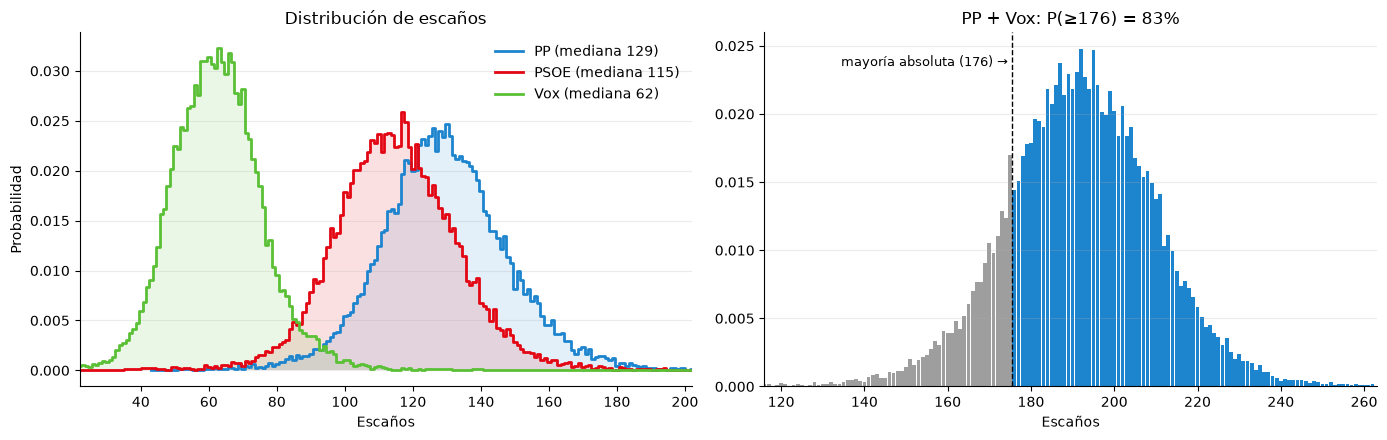

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for p in ["PP", "PSOE", "Vox"]:
    vc = ESC[p].value_counts(normalize=True).sort_index()
    axes[0].step(vc.index, vc.values, where="mid", color=COLORES[p], lw=2, label=f"{p} (mediana {int(ESC[p].median())})")
    axes[0].fill_between(vc.index, vc.values, step="mid", color=COLORES[p], alpha=.12, lw=0)
lo, hi = ESC[["PP", "PSOE", "Vox"]].stack().quantile([.001, .999]); axes[0].set_xlim(lo - 3, hi + 3)
axes[0].set_xlabel("Escaños"); axes[0].set_ylabel("Probabilidad"); axes[0].set_title("Distribución de escaños"); axes[0].legend(frameon=False)
s = ESC[["PP", "Vox"]].sum(axis=1); vc = s.value_counts(normalize=True).sort_index()
axes[1].bar(vc.index, vc.values, color=np.where(vc.index >= 176, "#1d84ce", "#9e9e9e"), width=0.9)
axes[1].set_xlim(s.quantile(.001) - 3, s.quantile(.999) + 3)
axes[1].axvline(175.5, color="k", ls="--", lw=1); axes[1].text(174.5, vc.max() * .95, "mayoría absoluta (176) →", fontsize=9, ha="right")
axes[1].set_title(f"PP + Vox: P(≥176) = {(s >= 176).mean():.0%}"); axes[1].set_xlabel("Escaños")
for ax in axes: ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="y", alpha=.25)
plt.tight_layout(); plt.show()

### 9.2 Escaños esperados por provincia (escenario central)
Media de escaños en 4.000 simulaciones sin error sistemático común. Un 0,5 indica un escaño en disputa al 50 %. Es orientativa: el total de referencia es el de la tabla 9.1.

In [29]:
rng = rng_para("§9.2")
cnt_prov, _ = simular(pi_T[idx[:4000]], mapa26, rng, SIGMA_SIST, error_sistematico=False, con_ajuste=USAR_REGIONALES, por_provincia=True)
E_prov = pd.DataFrame(cnt_prov.mean(0), index=[NOMBRE_ES.get(p, p) for p in PROV], columns=CAND).drop(columns="OTROS")
E_prov = E_prov.loc[:, E_prov.sum() > 0.05].round(1)
E_prov.insert(0, "escaños", escanos26.to_numpy())
E_prov.sort_values("escaños", ascending=False)

,escaños,PP,PSOE,Vox,FA,FV,ERC,Junts,Bildu,PNV,BNG,CCa,AA
Madrid,38,15.5,10.6,8.3,3.6,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Barcelona,32,4.9,12.5,4.1,2.1,0.0,5.8,2.6,0.0,0.0,0.0,0.0,0.0
Valencia,16,5.5,4.9,3.6,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Alicante,12,4.6,3.5,2.8,0.0,1.1,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Sevilla,12,4.1,4.2,2.1,0.2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.5
Málaga,11,4.4,3.1,2.5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
Murcia,10,4.3,2.3,3.4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Las Palmas,8,2.2,3.1,2.1,0.5,0.0,0.0,0.0,0.0,0.0,0.0,0.1,0.0
Bizkaia,8,1.0,2.9,0.0,0.0,0.0,0.0,0.0,2.1,2.0,0.0,0.0,0.0
Cádiz,8,2.9,2.6,1.4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.1


### 9.3 ¿Quién gana en cada provincia y con qué seguridad?
Ahora **con toda la incertidumbre** (incluido el error sistemático): en cada simulación se mira qué candidatura es la más votada en cada provincia. `P_ganador` es el porcentaje de simulaciones en que gana la favorita; por debajo del 60 % la provincia está realmente en disputa. También se guardan los escaños y el voto medios por provincia (hoja `provincias` del Excel), que alimentan los mapas del README, junto con un **escenario típico**: la simulación cuyo total nacional está más cerca de la mediana y que más se parece a la media de cada provincia (un reparto concreto y coherente, útil para dibujar el mapa de escaños).

In [30]:
rng = rng_para("§9.3")
N_PROV = 8000
E_pp, _, V_pp = simular(pi_T[idx[:N_PROV]], mapa26, rng, SIGMA_SIST, DF_T_SISTEMATICO, con_ajuste=USAR_REGIONALES,
                        bloque=VEC_BLOQUE, rho=RHO, por_provincia=True, voto_prov=True)
jv = [j for j, c in enumerate(CAND) if c != "OTROS"]
ganador = np.array(CAND)[jv][V_pp[:, :, jv].argmax(-1)]            # S × P: candidatura más votada
# escenario típico: entre las simulaciones con el total nacional más cercano a la mediana,
# la más parecida a la media de cada provincia (un reparto real y coherente, para el mapa de escaños)
nac_pp = E_pp.sum(1)
dist_nac = np.abs(nac_pp - np.median(nac_pp, axis=0)).sum(1)
cerca = np.flatnonzero(dist_nac <= np.sort(dist_nac)[4])            # las más cercanas al total mediano (al menos 5)
S_TIPICA = int(cerca[np.argmin(((E_pp[cerca] - E_pp.mean(0)) ** 2).sum((1, 2)))])
print("Escenario típico (total nacional):", {CAND[j]: int(nac_pp[S_TIPICA, j]) for j in jv if nac_pp[S_TIPICA, j] > 0})
filas = []
for p, prov in enumerate(PROV):
    vc = pd.Series(ganador[:, p]).value_counts(normalize=True)
    filas.append({"provincia": NOMBRE_ES.get(prov, prov), "prov_wiki": prov, "escaños": int(escanos26[prov]),
                  "ganador": vc.index[0], "P_ganador": round(float(vc.iloc[0]), 3),
                  "segundo": vc.index[1] if len(vc) > 1 else "", "P_segundo": round(float(vc.iloc[1]), 3) if len(vc) > 1 else 0.0,
                  **{f"voto_{CAND[j]}": round(float(V_pp[:, p, j].mean()), 2) for j in jv},
                  **{f"esc_{CAND[j]}": round(float(E_pp[:, p, j].mean()), 2) for j in jv},
                  **{f"tipico_{CAND[j]}": int(E_pp[S_TIPICA, p, j]) for j in jv}})
PROVINCIAS = pd.DataFrame(filas).set_index("provincia")
print("Provincias en las que cada partido es el favorito:", PROVINCIAS.ganador.value_counts().to_dict())
print(f"Provincias en disputa (favorito gana en menos del 60 % de las simulaciones): {(PROVINCIAS.P_ganador < .6).sum()}")
PROVINCIAS[["escaños", "ganador", "P_ganador", "segundo", "P_segundo"]].sort_values("P_ganador").head(12)

Escenario típico (total nacional): {'PP': 132, 'PSOE': 114, 'Vox': 64, 'FA': 7, 'FV': 3, 'ERC': 9, 'Junts': 4, 'Bildu': 6, 'PNV': 4, 'BNG': 2, 'CCa': 2, 'AA': 3}
Provincias en las que cada partido es el favorito: {'PP': 42, 'PSOE': 9, 'Bildu': 1}
Provincias en disputa (favorito gana en menos del 60 % de las simulaciones): 6


,escaños,ganador,P_ganador,segundo,P_segundo
provincia,,,,,
Ceuta,1,PP,0.464,Vox,0.383
Sevilla,12,PSOE,0.540,PP,0.455
Badajoz,5,PP,0.542,PSOE,0.443
Guadalajara,3,PP,0.546,PSOE,0.229
Santa Cruz de Tenerife,7,PSOE,0.565,PP,0.430
Cáceres,4,PP,0.567,PSOE,0.420
Toledo,6,PP,0.602,Vox,0.213
Huelva,5,PP,0.612,PSOE,0.382
Cádiz,8,PP,0.624,PSOE,0.361


### 9.4 Comprobación: ¿es suficiente la incertidumbre?
Lo que decide la mayoría es la **distancia entre bloques**. Si el modelo fuera más «seguro» que el historial de las encuestas, sus probabilidades serían engañosas. Se compara la dispersión simulada de la brecha derecha (PP + Vox + SALF) − izquierda (PSOE + FA + FV + Podemos) con el error que tuvieron las encuestas en esa misma brecha en 2015–2023 (sección 6).

In [31]:
der, izq = ["PP", "Vox", "SALF"], ["PSOE", "FA", "FV", "Podemos"]
brecha_sim = VOTO[der].sum(axis=1) - VOTO[izq].sum(axis=1)
SD_BRECHA_MODELO = float(brecha_sim.std())
print(f"Brecha derecha − izquierda: mediana {brecha_sim.median():+.1f} pts (IC80 {brecha_sim.quantile(.1):+.1f} a {brecha_sim.quantile(.9):+.1f})")
print(f"Incertidumbre del modelo (desv. típica): {SD_BRECHA_MODELO:.1f} pts | error histórico de las encuestas en la brecha (RMS): {BRECHA_HIST_RMS:.1f} pts")
print("→ " + ("Coherente: el modelo es al menos tan incierto como lo han sido las encuestas." if SD_BRECHA_MODELO >= 0.9 * BRECHA_HIST_RMS
              else "Atención: el modelo es más seguro de lo que justifica el historial de las encuestas."))

Brecha derecha − izquierda: mediana +14.4 pts (IC80 +5.3 a +23.6)
Incertidumbre del modelo (desv. típica): 7.5 pts | error histórico de las encuestas en la brecha (RMS): 5.2 pts
→ Coherente: el modelo es al menos tan incierto como lo han sido las encuestas.


## 10. Escenario «las encuestas fallan como en 2023»

En lugar de un error sistemático aleatorio se aplica exactamente el de la media de encuestas privadas de 2023: el voto «real» de cada partido es su estimación × *resultado 2023 / media de encuestas 2023* (el error del espacio de Sumar se aplica a FA, FV y Podemos). El resto de la incertidumbre se mantiene. Al fijar el error en vez de sortearlo, es una **prueba de estrés**, no una predicción alternativa. Después se repite con el error de cada elección desde 2015.

In [32]:
rng = rng_para("§10")
def shift_desde(eleccion):
    e = err[err.eleccion == eleccion].set_index("partido"); sh = np.zeros(K)
    for k, p in enumerate(PARTIDOS):
        src = {"PP": "PP", "PSOE": "PSOE", "Vox": "Vox", "FAFV": "IZQ", "Podemos": "IZQ"}.get(p)
        if src in e.index: sh[k] = -e.loc[src, "error_logit"]
    return sh

ESC23, VOTO23 = simular(pi_T[idx], mapa26, rng, SIGMA_SIST, shift=shift_desde("2023"), error_sistematico=False, con_ajuste=USAR_REGIONALES)
comparativa = pd.DataFrame({"base_voto": VOTO.mean(), "esc23_voto": VOTO23.mean(),
                            "base_esc_mediana": ESC.median(), "esc23_esc_mediana": ESC23.median()}).drop(index="OTROS")
comparativa["Δ escaños"] = comparativa.esc23_esc_mediana - comparativa.base_esc_mediana
display(comparativa.sort_values("base_esc_mediana", ascending=False).round(1))
tb23 = resumen_bloques(ESC23)
pd.DataFrame({"Base": tabla_bloques["probabilidad"], "Escenario 2023": tb23["probabilidad"],
              "Base mediana": tabla_bloques["mediana"], "Escenario 2023 mediana": tb23["mediana"]}).style.format(
              {"Base": "{:.1%}", "Escenario 2023": "{:.1%}", "Base mediana": "{:.0f}", "Escenario 2023 mediana": "{:.0f}"}, na_rep="")

,base_voto,esc23_voto,base_esc_mediana,esc23_esc_mediana,Δ escaños
PP,31.0,29.0,129.0,119.0,-10.0
PSOE,28.5,33.1,115.0,138.0,23.0
Vox,18.0,16.5,62.0,55.0,-7.0
ERC,2.5,2.5,9.0,9.0,0.0
Bildu,1.5,1.4,7.0,7.0,0.0
FA,5.4,4.9,7.0,5.0,-2.0
Junts,1.3,1.3,4.0,4.0,0.0
FV,1.3,1.2,3.0,3.0,0.0
AA,1.7,1.7,3.0,3.0,0.0
PNV,0.9,0.9,3.0,3.0,0.0


,Base,Escenario 2023,Base mediana,Escenario 2023 mediana
bloque,,,,
PP + Vox,82.8%,28.7%,192,173
PP + Vox + SALF,82.9%,28.8%,192,173
PSOE + FA + FV + Podemos,0.8%,0.0%,125,146
Bloque investidura 2023 sin Junts,10.1%,17.1%,153,172
Bloque investidura 2023 con Junts,15.4%,61.1%,158,177
PP primera fuerza en escaños,67.2%,0.2%,,
PP ≥ PSOE+FA+FV+Podemos,55.3%,0.0%,,


In [33]:
rng = rng_para("§10b")
replay = []
for e in FECHAS_ELEC:
    E_, _ = simular(pi_T[idx[:8000]], mapa26, rng, SIGMA_SIST, shift=shift_desde(e), error_sistematico=False, con_ajuste=USAR_REGIONALES)
    replay.append({"error como en": e, "PP": E_.PP.median(), "PSOE": E_.PSOE.median(), "Vox": E_.Vox.median(),
                   "FA+FV+Podemos": E_[["FA", "FV", "Podemos"]].sum(axis=1).median(), "PP+Vox (mediana)": E_[["PP", "Vox"]].sum(axis=1).median(),
                   "P(PP+Vox ≥176)": (E_[["PP", "Vox"]].sum(axis=1) >= 176).mean(), "P(PP > PSOE)": (E_.PP > E_.PSOE).mean()})
replay.append({"error como en": "BASE (error aleatorio)", "PP": ESC.PP.median(), "PSOE": ESC.PSOE.median(), "Vox": ESC.Vox.median(),
               "FA+FV+Podemos": ESC[["FA", "FV", "Podemos"]].sum(axis=1).median(), "PP+Vox (mediana)": ESC[["PP", "Vox"]].sum(axis=1).median(),
               "P(PP+Vox ≥176)": (ESC[["PP", "Vox"]].sum(axis=1) >= 176).mean(), "P(PP > PSOE)": (ESC.PP > ESC.PSOE).mean()})
replay = pd.DataFrame(replay).set_index("error como en")
replay.style.format({"P(PP+Vox ≥176)": "{:.0%}", "P(PP > PSOE)": "{:.0%}"}, precision=0)

,PP,PSOE,Vox,FA+FV+Podemos,PP+Vox (mediana),P(PP+Vox ≥176),P(PP > PSOE)
error como en,,,,,,,
2015,131,120,57,13,188,100%,93%
2016,144,117,55,6,199,100%,100%
April 2019,106,127,66,15,172,18%,0%
November 2019,121,115,74,10,196,100%,85%
2023,119,138,55,8,174,28%,0%
BASE (error aleatorio),129,115,62,10,192,83%,67%


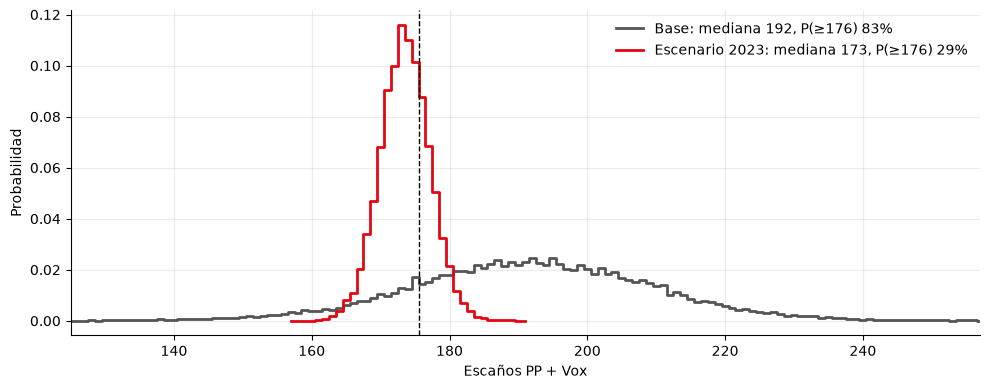

In [34]:
fig, ax = plt.subplots(figsize=(10, 4))
for E_, lab, col in [(ESC, "Base", "#555555"), (ESC23, "Escenario 2023", "#e30613")]:
    s = E_[["PP", "Vox"]].sum(axis=1); vc = s.value_counts(normalize=True).sort_index()
    ax.step(vc.index, vc.values, where="mid", color=col, lw=2, label=f"{lab}: mediana {int(s.median())}, P(≥176) {(s >= 176).mean():.0%}")
ax.axvline(175.5, color="k", ls="--", lw=1)
both = pd.concat([ESC[["PP", "Vox"]].sum(axis=1), ESC23[["PP", "Vox"]].sum(axis=1)])
ax.set_xlim(both.quantile(.001) - 3, both.quantile(.999) + 3)
ax.set_xlabel("Escaños PP + Vox"); ax.set_ylabel("Probabilidad"); ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False); ax.grid(alpha=.25); plt.tight_layout(); plt.show()

## 11. Prueba hacia atrás: el modelo aplicado a 2023

**Pregunta:** si este mismo notebook se hubiera ejecutado el 18 de julio de 2023 (el día siguiente al último día legal de publicación de encuestas), ¿qué habría dicho, y en qué habría acertado o fallado?

**Regla de oro: nada de información del futuro.** Para 2023 se usa exactamente el mismo motor, pero solo con lo que se sabía entonces:

| Pieza | 2026 (pronóstico) | 2023 (prueba) |
|---|---|---|
| Encuestas nacionales | jul–nov 2026 | feb–jul 2023 (mismos ~5 meses antes) |
| Encuestas autonómicas/provinciales | desde la convocatoria | desde la convocatoria (30-may-2023) |
| Geografía base | resultados 2023 | resultados de noviembre de 2019 |
| Pesos provinciales | votos válidos 2023 | votos válidos 2019 |
| Ruido territorial | calibrado 2019→2023 | calibrado 2016→2019 |
| Error sistemático histórico y correlación de bloque | 2015–2023 | **solo 2015–2019** |
| Error no muestral de encuestas subnacionales | calibrado con 2023 (§8.1) | valor *a priori* (0,15) |
| Escaños por provincia | Real Decreto 2026 | reparto oficial de 2023 |

Partidos de 2023: Sumar reúne Sumar + Podemos (fueron juntos); Ciudadanos no se presentó (su voto de 2019 va a «otros» en la base); Navarra Suma de 2019 se reparte 60/40 entre UPN y PP, que en 2023 fueron por separado.

In [35]:
# FE23, INI23, CONV23, mapear23 y sub23 se definen en §8.1
P23M = ["PP", "PSOE", "Vox", "Sumar", "ERC", "Junts", "Bildu", "PNV", "BNG", "CCa", "UPN", "CUP"]
MAPA_NAC23 = {"PP": ["PP"], "PSOE": ["PSOE"], "Vox": ["Vox"], "Sumar": ["Sumar", "Podemos"], "ERC": ["ERC", "ERC–Sobiranistes"],
              "Junts": ["Junts"], "Bildu": ["EH Bildu"], "PNV": ["PNV"], "BNG": ["BNG"], "CCa": ["CCa", "CC–NCa"], "UPN": ["UPN"], "CUP": ["CUP"]}
enc23_all, enc23 = preparar_encuestas(D["encuestas23_raw"], MAPA_NAC23, 2023, INI23, FE23, CFG)
print(f"2023: {len(enc23)} encuestas de {enc23.casa.nunique()} empresas ({enc23.fin.min():%d-%m} → {enc23.fin.max():%d-%m-%Y})")
fit23 = ajustar_modelo(enc23, P23M, INI23, FE23, draws=DRAWS, tune=TUNE, chains=CHAINS, seed=SEED, sampler=NUTS_SAMPLER)
print(f"Muestreo ({fit23['sampler']}): {fit23['segundos']:.0f} s"); diagnostico(fit23["idata"])

2023: 115 encuestas de 23 empresas (02-04 → 17-07-2023)


Muestreo (nutpie): 48 s


{'divergencias': 0,
 'rhat_hiper': 1.01,
 'ess_hiper': 604,
 'rhat_dia_E': 1.01,
 'ess_dia_E': 837,
 'criterios_ok': True}

In [36]:
# --- geografía de 2023 construida con 2019 ---
CAND23 = P23M + ["OTROS"]
base23 = pd.DataFrame(0.0, index=PROV, columns=CAND23)
for p in ["PP", "PSOE", "Vox", "ERC", "Junts", "Bildu", "PNV", "BNG", "CCa", "CUP"]: base23[p] = res19[p]
base23["Sumar"] = res19.UP + res19.MP
base23.loc["Navarre", "PP"] = 0.4 * res19.loc["Navarre", "NA"]; base23.loc["Navarre", "UPN"] = 0.6 * res19.loc["Navarre", "NA"]
base23["OTROS"] = (100 - res19[["PP","PSOE","Vox","UP","MP","ERC","Junts","PNV","Bildu","CUP","CCa","BNG","NA"]].sum(axis=1)).clip(lower=0.5)
escanos23 = res23[[c for c in res23.columns if c.startswith("S_")]].sum(axis=1).astype(int)
r16x = res16.assign(IZQ=res16.UP)
SD_REG23, SD_PROV23, _ = calibrar_ruido(r19x, r16x, t19x, pd.concat([tot16, pd.Series({"IZQ": tot16.UP})]),
                                        {"PP": ("PP", "PP"), "PSOE": ("PSOE", "PSOE"), "IZQ": ("IZQ", "IZQ"), "Cs": ("Cs", "Cs")})
SIGMA_SIST23 = float(np.sqrt((err[err.eleccion != "2023"].error_logit ** 2).mean()))
mapa23 = Mapa(base23, D["validos19"], escanos23, SD_REG23, SD_PROV23, CAND23, lambda pin, rng: pin)
RHO23 = estimar_rho(err[err.eleccion != "2023"], SIGMA_SIST23) if RHO_BLOQUE is None else RHO_BLOQUE
VEC_BLOQUE23 = np.array([{"PP": 1, "Vox": 1, "UPN": 1, "PSOE": -1, "Sumar": -1}.get(p, 0) for p in P23M])
print(f"Ruido 2016→2019: σ_reg={SD_REG23:.3f} σ_prov={SD_PROV23:.3f} | σ sistemático (2015–2019) = {SIGMA_SIST23:.3f} | ρ bloque = {RHO23:.2f}")

# sin la calibración de §8.1: usarla sería meter información del propio 2023 en la prueba
CFG23 = {**CFG, "SIGMA_CASA_SUB": SIGMA_CASA_SUB_PRIOR}
obs23 = ajuste_regional(sub23, mapa23, fit23, CFG23, INI23)
print(f"Encuestas subnacionales 2023: {sub23[['firm','date','unidad']].drop_duplicates().shape[0]} en {sub23.unidad.nunique()} territorios")

Ruido 2016→2019: σ_reg=0.222 σ_prov=0.070 | σ sistemático (2015–2019) = 0.167 | ρ bloque = 0.04
Encuestas subnacionales 2023: 26 en 15 territorios


In [37]:
rng = rng_para("§11")
idx23 = rng.integers(0, fit23["pi_T"].shape[0], N_SIM)
real_esc23 = pd.Series({p: int(res23["S_" + p].sum()) if "S_" + p in res23 else 0 for p in P23M})
real_voto23 = pd.Series({p: float(tot23[p]) if p in tot23 else np.nan for p in P23M})
real_voto23["CUP"] = float(D["hist"][D["hist"].eleccion == "2023"].iloc[0].get("CUP", 0.3))
v = real_voto23.to_numpy() / 100; oraculo = np.tile(np.append(v, 1 - v.sum()), (N_SIM, 1))
BT = {
    "Modelo completo": simular(fit23["pi_T"][idx23], mapa23, rng, SIGMA_SIST23, con_ajuste=True, bloque=VEC_BLOQUE23, rho=RHO23)[0],
    "Sin encuestas regionales": simular(fit23["pi_T"][idx23], mapa23, rng, SIGMA_SIST23, con_ajuste=False, bloque=VEC_BLOQUE23, rho=RHO23)[0],
    "Sin error sistemático": simular(fit23["pi_T"][idx23], mapa23, rng, SIGMA_SIST23, error_sistematico=False, con_ajuste=True)[0],
    "Oráculo: voto nacional real": simular(oraculo, mapa23, rng, SIGMA_SIST23, error_sistematico=False, con_ajuste=True)[0],
}

### 11.1 Voto nacional: modelo frente a la media simple de encuestas

In [38]:
ult23 = enc23[(enc23.fin >= FE23 - pd.Timedelta(days=13)) & (enc23.casa != "CIS")].sort_values("fin").groupby("casa").tail(1)
voto_bt = pd.DataFrame({"resultado_real": real_voto23,
                        "media_simple_ult_semana": ult23[P23M].mean(),
                        "modelo": pd.Series(fit23["pi_T"].mean(0)[:len(P23M)] * 100, index=P23M)})
voto_bt["error_media_simple"] = voto_bt.media_simple_ult_semana - voto_bt.resultado_real
voto_bt["error_modelo"] = voto_bt.modelo - voto_bt.resultado_real
print(f"Error absoluto medio — media simple: {voto_bt.error_media_simple.abs().mean():.2f} pts | modelo: {voto_bt.error_modelo.abs().mean():.2f} pts")
voto_bt.round(2)

Error absoluto medio — media simple: 0.65 pts | modelo: 0.59 pts


,resultado_real,media_simple_ult_semana,modelo,error_media_simple,error_modelo
PP,33.1,34.25,33.63,1.15,0.53
PSOE,31.7,28.18,28.11,-3.52,-3.59
Vox,12.4,13.18,13.03,0.78,0.63
Sumar,12.3,13.17,13.13,0.87,0.83
ERC,1.9,2.18,2.13,0.28,0.23
Junts,1.6,1.98,1.93,0.38,0.33
Bildu,1.4,1.35,1.29,-0.05,-0.11
PNV,1.1,1.25,1.26,0.15,0.16
BNG,0.6,0.82,0.84,0.22,0.24
CCa,0.5,0.33,0.37,-0.17,-0.13


### 11.2 Escaños: predicción frente a la realidad
`percentil` = posición del resultado real dentro de la distribución simulada (0,5 = justo en la mediana; cerca de 0 o 1 = sorpresa). Un modelo bien calibrado debería contener el resultado real en su intervalo del 80 % aproximadamente 8 de cada 10 veces.

In [39]:
def evaluar(E, real):
    filas = []
    for p in P23M:
        e = E[p]; r = real[p]
        filas.append(dict(partido=p, real=r, mediana=e.median(), IC80=f"{int(e.quantile(.1))}–{int(e.quantile(.9))}",
                          dentro_IC80=bool(e.quantile(.1) <= r <= e.quantile(.9)), dentro_IC95=bool(e.quantile(.025) <= r <= e.quantile(.975)),
                          percentil=round(float((e < r).mean() + 0.5 * (e == r).mean()), 2)))
    return pd.DataFrame(filas).set_index("partido")
eval_completo = evaluar(BT["Modelo completo"], real_esc23)
display(eval_completo)

resumen_bt = []
for nombre, E in BT.items():
    ev = evaluar(E, real_esc23); pv = E[["PP", "Vox"]].sum(axis=1)
    resumen_bt.append({"variante": nombre, "error total escaños (Σ|mediana−real|)": int((ev.mediana - ev.real).abs().sum()),
                       "cobertura IC80": ev.dentro_IC80.mean(), "cobertura IC95": ev.dentro_IC95.mean(),
                       "PP+Vox mediana": int(pv.median()), "PP+Vox IC80": f"{int(pv.quantile(.1))}–{int(pv.quantile(.9))}",
                       "P(PP+Vox ≥176)": (pv >= 176).mean()})
resumen_bt = pd.DataFrame(resumen_bt).set_index("variante")
print(f"Resultado real: PP+Vox = {real_esc23.PP + real_esc23.Vox} escaños (sin mayoría absoluta)")
resumen_bt.style.format({"cobertura IC80": "{:.0%}", "cobertura IC95": "{:.0%}", "P(PP+Vox ≥176)": "{:.0%}"})

,real,mediana,IC80,dentro_IC80,dentro_IC95,percentil
partido,,,,,,
PP,137,142.0,117–167,True,True,0.39
PSOE,121,107.0,86–132,True,True,0.77
Vox,33,36.0,24–49,True,True,0.39
Sumar,31,33.0,23–44,True,True,0.41
ERC,7,7.0,6–9,True,True,0.49
Junts,7,7.0,5–9,True,True,0.49
Bildu,6,5.0,3–7,True,True,0.66
PNV,5,5.0,3–6,True,True,0.43
BNG,1,2.0,1–3,True,True,0.10


Resultado real: PP+Vox = 170 escaños (sin mayoría absoluta)


,error total escaños (Σ|mediana−real|),cobertura IC80,cobertura IC95,PP+Vox mediana,PP+Vox IC80,P(PP+Vox ≥176)
variante,,,,,,
Modelo completo,27,100%,100%,179,154–203,57%
Sin encuestas regionales,25,100%,100%,178,153–203,56%
Sin error sistemático,27,75%,83%,180,173–186,80%
Oráculo: voto nacional real,10,92%,100%,171,167–175,6%


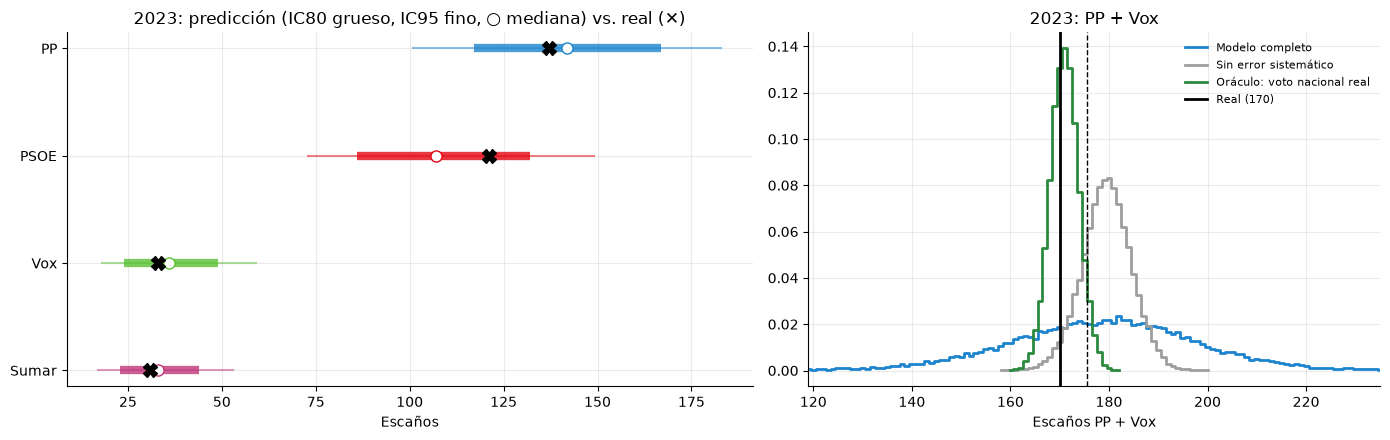

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [1.2, 1]})
E = BT["Modelo completo"]; ps = ["PP", "PSOE", "Vox", "Sumar"]
for i, p in enumerate(ps):
    q = E[p].quantile([.025, .1, .5, .9, .975])
    axes[0].plot([q[.025], q[.975]], [i, i], color=COLORES[p], lw=1.5, alpha=.5)
    axes[0].plot([q[.1], q[.9]], [i, i], color=COLORES[p], lw=6, alpha=.8, solid_capstyle="butt")
    axes[0].plot(q[.5], i, "o", color="white", mec=COLORES[p], ms=8)
    axes[0].plot(real_esc23[p], i, "kX", ms=10)
axes[0].set_yticks(range(len(ps))); axes[0].set_yticklabels(ps); axes[0].invert_yaxis()
axes[0].set_xlabel("Escaños"); axes[0].set_title("2023: predicción (IC80 grueso, IC95 fino, ○ mediana) vs. real (✕)")
for nombre, col in [("Modelo completo", "#1d84ce"), ("Sin error sistemático", "#9e9e9e"), ("Oráculo: voto nacional real", "#2b8a3e")]:
    s = BT[nombre][["PP", "Vox"]].sum(axis=1); vc = s.value_counts(normalize=True).sort_index()
    axes[1].step(vc.index, vc.values, where="mid", color=col, lw=2, label=nombre)
axes[1].axvline(real_esc23.PP + real_esc23.Vox, color="k", lw=2, label=f"Real ({real_esc23.PP + real_esc23.Vox})")
axes[1].axvline(175.5, color="k", ls="--", lw=1)
s_all = BT["Modelo completo"][["PP", "Vox"]].sum(axis=1); axes[1].set_xlim(s_all.quantile(.005), s_all.quantile(.995))
axes[1].set_xlabel("Escaños PP + Vox"); axes[1].set_title("2023: PP + Vox"); axes[1].legend(frameon=False, fontsize=8)
for ax in axes: ax.spines[["top", "right"]].set_visible(False); ax.grid(alpha=.25)
plt.tight_layout(); plt.show()

### 11.3 Qué enseña la prueba

La celda siguiente imprime las conclusiones con los números de esta ejecución. Las claves que hay que mirar:

- **El motor de escaños es fiable.** Con el voto nacional real (el «oráculo»), el error de traducción a escaños es pequeño y PP+Vox cae prácticamente en su valor real. El reparto provincial y D'Hondt no son el cuello de botella.
- **El error principal viene de las encuestas**, no del modelo: en 2023 toda la industria infravaloró al PSOE. Corregir los efectos casa mejora la media simple, sobre todo en el PP, pero no puede arreglar un fallo común a todas las empresas.
- **Por eso el término de error sistemático es imprescindible.** Sin él, el modelo habría dado una mayoría de PP+Vox casi segura y varios resultados reales habrían caído fuera de sus intervalos; con él, el resultado real queda dentro del intervalo del 80 % aunque el escenario más probable no se cumpliera.
- **Las encuestas regionales apenas cambiaron nada en 2023.** Con una sola elección no se puede afirmar que ayuden; en 2026 se mantienen porque las coaliciones nuevas (CHA–FA, UPC, Compromís–FV, Podemos dentro de ERC/FV) hacen la geografía de partida menos fiable, que es justo lo que informan. Se puede desactivar con `USAR_REGIONALES = False`.
- **Una sola elección es poca evidencia.** La prueba muestra que el método es coherente y honesto con la incertidumbre, no que vaya a acertar.

In [41]:
oc = BT["Oráculo: voto nacional real"]; ev_oc = evaluar(oc, real_esc23)
rb = resumen_bt
print(f"• Oráculo (voto nacional real): error total {rb.loc['Oráculo: voto nacional real', 'error total escaños (Σ|mediana−real|)']} escaños; "
      f"PP+Vox mediana {rb.loc['Oráculo: voto nacional real', 'PP+Vox mediana']} vs real {real_esc23.PP + real_esc23.Vox}.")
print(f"• Voto nacional: error medio {voto_bt.error_modelo.abs().mean():.2f} pts (modelo) vs {voto_bt.error_media_simple.abs().mean():.2f} pts (media simple); "
      f"PSOE {voto_bt.loc['PSOE','error_modelo']:+.1f} pts, PP {voto_bt.loc['PP','error_modelo']:+.1f} pts.")
print(f"• Modelo completo: P(PP+Vox ≥176) = {rb.loc['Modelo completo','P(PP+Vox ≥176)']:.0%}; cobertura IC80 = {rb.loc['Modelo completo','cobertura IC80']:.0%}; "
      f"sin error sistemático habría sido {rb.loc['Sin error sistemático','P(PP+Vox ≥176)']:.0%} con cobertura IC80 = {rb.loc['Sin error sistemático','cobertura IC80']:.0%}.")
print(f"• Encuestas regionales: error total {rb.loc['Modelo completo','error total escaños (Σ|mediana−real|)']} (con) vs "
      f"{rb.loc['Sin encuestas regionales','error total escaños (Σ|mediana−real|)']} (sin).")

• Oráculo (voto nacional real): error total 10 escaños; PP+Vox mediana 171 vs real 170.
• Voto nacional: error medio 0.59 pts (modelo) vs 0.65 pts (media simple); PSOE -3.6 pts, PP +0.5 pts.
• Modelo completo: P(PP+Vox ≥176) = 57%; cobertura IC80 = 100%; sin error sistemático habría sido 80% con cobertura IC80 = 75%.
• Encuestas regionales: error total 27 (con) vs 25 (sin).


## 12. Resumen automático

In [42]:
mod = ESC[["PP", "PSOE", "Vox", "FA", "FV", "Podemos"]].median().astype(int)
pv = ESC[["PP", "Vox"]].sum(axis=1); pv23 = ESC23[["PP", "Vox"]].sum(axis=1)
print(f"Fuente de datos: {FUENTE}. Encuestas nacionales: {len(enc)} de {enc.casa.nunique()} empresas ({INICIO_VENTANA:%d-%m} → {enc.fin.max():%d-%m-%Y}); "
      f"subnacionales: {len(enc_sub)} en {enc_sub.unidad.nunique()} territorios.")
print("Voto estimado (media de encuestadoras privadas, corregida):", ", ".join(f"{p} {tabla_nac.loc[p, 'media']:.1f} %" for p in ["PP", "PSOE", "Vox", "FAFV"]))
print("Escaños (mediana):", ", ".join(f"{p} {v}" for p, v in mod.items()))
print(f"PP primera fuerza en escaños: {(ESC.PP > ESC.PSOE).mean():.0%} de las simulaciones.")
print(f"PP + Vox: mediana {int(pv.median())} escaños; P(≥176) = {(pv >= 176).mean():.0%}.")
print(f"Si las encuestas fallan como en 2023: PP + Vox mediana {int(pv23.median())}; P(≥176) = {(pv23 >= 176).mean():.0%}.")
print(f"Prueba con 2023: el modelo habría dado P(PP+Vox ≥176) = {rb.loc['Modelo completo','P(PP+Vox ≥176)']:.0%}; el resultado real "
      f"({real_esc23.PP + real_esc23.Vox}) quedó dentro de su intervalo del 80 % ({rb.loc['Modelo completo','PP+Vox IC80']}).")
print(f"Supuestos calibrados: error sistemático σ = {SIGMA_SIST:.3f} (logit), correlación de bloque ρ = {RHO:.2f}, "
      f"error de encuestas subnacionales σ = {CFG['SIGMA_CASA_SUB']:.3f}; muestreador: {fit26['sampler']}.")

Fuente de datos: copia congelada (24-nov-2026). Encuestas nacionales: 107 de 28 empresas (01-07 → 23-11-2026); subnacionales: 49 en 27 territorios.
Voto estimado (media de encuestadoras privadas, corregida): PP 31.1 %, PSOE 28.5 %, Vox 18.0 %, FAFV 6.7 %
Escaños (mediana): PP 129, PSOE 115, Vox 62, FA 7, FV 3, Podemos 0
PP primera fuerza en escaños: 67% de las simulaciones.
PP + Vox: mediana 192 escaños; P(≥176) = 83%.
Si las encuestas fallan como en 2023: PP + Vox mediana 173; P(≥176) = 29%.
Prueba con 2023: el modelo habría dado P(PP+Vox ≥176) = 57%; el resultado real (170) quedó dentro de su intervalo del 80 % (154–203).
Supuestos calibrados: error sistemático σ = 0.158 (logit), correlación de bloque ρ = 0.04, error de encuestas subnacionales σ = 0.123; muestreador: nutpie.


## 13. Limitaciones

- **Las encuestas son la única fuente de información sobre 2026.** Si toda la industria comparte un sesgo nuevo, el modelo solo lo cubre a través del error sistemático histórico. La prueba de 2023 muestra que ese es el riesgo dominante.
- **La correlación del error por bloques se estima con solo cinco elecciones.** El valor de ρ es muy impreciso; la sección 9.3 comprueba que, aun así, la incertidumbre sobre la brecha derecha–izquierda es coherente con la histórica. Con `RHO_BLOQUE` se puede fijar a mano para probar escenarios.
- **El *swing* proporcional** supone que cada partido crece o cae de forma parecida en todo el territorio, más un ruido calibrado y las correcciones de las encuestas subnacionales. Formaciones nuevas (FA, SALF, Compromís–FV) se ubican con supuestos geográficos razonables pero no verificables.
- **Encuestas subnacionales:** solo se corrige el efecto casa de las empresas que también publican encuestas nacionales; para el resto se trata como ruido, de un tamaño calibrado con una sola elección (2023). En provincias con encuestas propias, la correlación con el resto de su comunidad se simplifica.
- **Participación:** se usa el peso de cada provincia en la elección anterior.
- **Trackings:** al eliminar solapamientos se pierde parte de su información; es preferible a contar las mismas entrevistas varias veces.
- **Partidos pequeños sin base** (Teruel Existe, UPL, Geroa Bai…) quedan en «otros» y nunca obtienen escaño.
- **La prueba hacia atrás es una sola elección.** Podría ampliarse a noviembre de 2019 con el mismo motor.

## 14. Exportar resultados

In [43]:
with pd.ExcelWriter("resultados_29N.xlsx") as xw:
    tabla_nac.to_excel(xw, sheet_name="voto_nacional")
    tabla_base.to_excel(xw, sheet_name="escanos_base")
    tabla_bloques.to_excel(xw, sheet_name="bloques_base")
    E_prov.to_excel(xw, sheet_name="escanos_provincia")
    comparativa.to_excel(xw, sheet_name="escenario_2023")
    replay.to_excel(xw, sheet_name="replay_errores")
    tabla_he.to_excel(xw, sheet_name="efectos_casa")
    efectos_reg.to_excel(xw, sheet_name="efectos_regionales")
    obs26.to_excel(xw, sheet_name="encuestas_subnacionales", index=False)
    voto_bt.to_excel(xw, sheet_name="backtest_2023_voto")
    eval_completo.to_excel(xw, sheet_name="backtest_2023_escanos")
    resumen_bt.to_excel(xw, sheet_name="backtest_2023_resumen")
    enc.drop(columns=["alt"]).to_excel(xw, sheet_name="encuestas_usadas", index=False)
    pd.Series({"fuente_datos": FUENTE, "muestreador": fit26["sampler"], "sigma_sistematico_logit": SIGMA_SIST,
               "rho_bloque": RHO, "sigma_encuestas_subnacionales": CFG["SIGMA_CASA_SUB"], "sd_regional": SD_REG,
               "sd_provincial": SD_PROV, "FV_sobre_FAFV": FV_MU, "simulaciones": N_SIM}, name="valor").to_excel(xw, sheet_name="supuestos")
    cal_sub.to_excel(xw, sheet_name="calibracion_subnacional", index=False)
    PROVINCIAS.to_excel(xw, sheet_name="provincias")
ESC.to_csv("simulaciones_escanos_base.csv.gz", index=False)
print("Guardado: resultados_29N.xlsx, simulaciones_escanos_base.csv.gz")

Guardado: resultados_29N.xlsx, simulaciones_escanos_base.csv.gz
